# 6BUIS017W Coursework: Market Analysis and Stock Segmentation Using RFM

Full analysis notebook: Task 1 (data preparation and features), Task 2 (segmentation and sensitivity) and the evidence for Task 3 (cluster profiles, sector composition, limitations). Every table and figure used in the report is saved to `outputs/`.

**How this notebook runs**

* First run: downloads the S&P 500 constituent list from Wikipedia and daily prices from Yahoo Finance, then saves everything into `data/`.
* Every later run: loads the saved files instead of downloading again, so results are identical each time. Commit the `data/` folder to GitHub.
* To force a fresh download, delete the files in `data/` (this changes the retrieval date, so record it).

**Study period:** 1 January 2021 to 1 January 2025, end date exclusive (last possible trading day 31 December 2024).

## 0. Setup and package versions

In [43]:
# Colab only: install packages that are not preinstalled
%pip install -q yfinance pyarrow

In [44]:
import os, sys, json, time, platform
import datetime as dt
from io import StringIO

import numpy as np
import pandas as pd
import requests
import yfinance as yf

START = dt.date(2021, 1, 1)
END = dt.date(2025, 1, 1)      # exclusive end date, as required by the brief
BENCHMARK = "^GSPC"
BATCH_SIZE = 100               # tickers per download request, keeps Yahoo rate limits happy

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
PATHS = {
    "html": os.path.join(DATA_DIR, "sp500_wikipedia_snapshot.html"),
    "constituents": os.path.join(DATA_DIR, "sp500_constituents.csv"),
    "prices_raw": os.path.join(DATA_DIR, "prices_raw.parquet"),
    "bench_raw": os.path.join(DATA_DIR, "gspc_raw.parquet"),
    "acq_meta": os.path.join(DATA_DIR, "acquisition_metadata.json"),
    "versions": os.path.join(DATA_DIR, "package_versions.json"),
    "exclusion_log": os.path.join(DATA_DIR, "exclusion_log.csv"),
    "prices_valid": os.path.join(DATA_DIR, "prices_validated.parquet"),
    "bench_valid": os.path.join(DATA_DIR, "gspc_validated.parquet"),
    "run_config": os.path.join(DATA_DIR, "run_config.json"),
}

versions = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__,
    "requests": requests.__version__,
}
with open(PATHS["versions"], "w") as f:
    json.dump(versions, f, indent=2)
pd.Series(versions, name="version").to_frame()

,version
python,3.13.18
platform,Linux-6.6.159+-x86_64-with-glibc2.39
pandas,2.2.3
numpy,2.4.6
yfinance,0.2.66
requests,2.32.4


## 1.1 Ticker selection and data acquisition

### 1.1.1 S&P 500 constituent list

The constituent table is read from Wikipedia with `pandas.read_html`. Wikipedia rejects the default Python request header, so the page is fetched with `requests` using a browser style header. The raw HTML is saved as a snapshot so the exact list used can be reproduced later.

In [45]:
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

if os.path.exists(PATHS["constituents"]):
    sp500 = pd.read_csv(PATHS["constituents"])
    print("Loaded cached constituent list.")
else:
    resp = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0 (university coursework)"}, timeout=30)
    resp.raise_for_status()
    with open(PATHS["html"], "w", encoding="utf8") as f:
        f.write(resp.text)
    sp500 = pd.read_html(StringIO(resp.text), attrs={"id": "constituents"})[0]
    sp500["retrieved_utc"] = dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")
    sp500.to_csv(PATHS["constituents"], index=False)
    print("Downloaded constituent list from Wikipedia.")

# Yahoo writes share classes with a hyphen where Wikipedia uses a dot (BRK.B becomes BRK-B)
sp500["yf_symbol"] = sp500["Symbol"].str.replace(".", "-", regex=False)

RETRIEVED_UTC = sp500["retrieved_utc"].iloc[0]
print("Retrieval date (UTC):", RETRIEVED_UTC)
print("Constituents:", len(sp500), "| unique symbols:", sp500["Symbol"].nunique())
sp500[["Symbol", "yf_symbol", "Security", "GICS Sector", "Date added"]].head()

Loaded cached constituent list.
Retrieval date (UTC): 2026-11-04T11:36:42+00:00
Constituents: 503 | unique symbols: 503


,Symbol,yf_symbol,Security,GICS Sector,Date added
0,MMM,MMM,3M,Industrials,1957-03-04
1,AOS,AOS,A. O. Smith,Industrials,2017-07-26
2,ABT,ABT,Abbott Laboratories,Health Care,1957-03-04
3,ABBV,ABBV,AbbVie,Health Care,2012-12-31
4,ACN,ACN,Accenture,Information Technology,2011-07-06


**Multiple share classes.** Some companies have more than one listed share class in the index (for example Alphabet GOOGL and GOOG). They are separate tickers with separate prices, so both are kept, but their returns will be almost identical. This is noted for the clustering and limitations discussion.

In [46]:
multi_class = sp500[sp500.duplicated("CIK", keep=False)].sort_values("CIK")
multi_class[["Symbol", "Security", "CIK"]]

,Symbol,Security,CIK
331,NWS,News Corp (Class B),1564708
330,NWSA,News Corp (Class A),1564708
19,GOOGL,Alphabet Inc. (Class A),1652044
20,GOOG,Alphabet Inc. (Class C),1652044
204,FOX,Fox Corporation (Class B),1754301
203,FOXA,Fox Corporation (Class A),1754301


### 1.1.2 Daily prices, adjusted prices, volume and benchmark

**Source choice:** `yfinance` (Yahoo Finance). It is free, returns unadjusted Close, dividend and split adjusted `Adj Close`, Volume, and the dividend and split history needed for corporate action checks. Its weaknesses: it is an unofficial interface, Yahoo can revise history without notice, and it rate limits large requests. Saving a snapshot addresses the first two for reproducibility.

Settings:

* `auto_adjust=False` keeps both `Close` and `Adj Close`. With the default (`True`) yfinance overwrites Close with adjusted prices and drops Adj Close.
* `actions=True` adds `Dividends` and `Stock Splits` columns for the corporate action checks in 1.2.
* `end` is exclusive in yfinance, matching the brief.

Data is stored in long format: one row per trading date and ticker. Dates where a ticker has no data (for example before it listed) appear as empty rows in the raw file and are handled explicitly in 1.2, never filled.

In [47]:
FIELDS = ["Open", "High", "Low", "Close", "Adj Close", "Volume", "Dividends", "Stock Splits"]


def to_long(wide):
    """Convert yfinance output (columns: Price by Ticker) into one row per Date and Ticker."""
    if not isinstance(wide.columns, pd.MultiIndex):
        raise ValueError("Expected yfinance MultiIndex columns (Price, Ticker)")
    names = list(wide.columns.names)
    tick_level = names.index("Ticker") if "Ticker" in names else 1
    frames = []
    for t in wide.columns.get_level_values(tick_level).unique():
        sub = wide.xs(t, axis=1, level=tick_level).reindex(columns=FIELDS).copy()
        sub["Ticker"] = t
        frames.append(sub)
    out = pd.concat(frames)
    out.index = pd.to_datetime(out.index).tz_localize(None)
    out.index.name = "Date"
    return out.reset_index()[["Date", "Ticker"] + FIELDS]


def download(tickers):
    wide = yf.download(tickers, start=START, end=END, auto_adjust=False, actions=True,
                       group_by="column", threads=True, progress=False)
    return to_long(wide)


def has_data(long_df):
    return long_df.groupby("Ticker")["Adj Close"].apply(lambda s: s.notna().any())

In [48]:
if os.path.exists(PATHS["prices_raw"]) and os.path.exists(PATHS["bench_raw"]):
    prices_raw = pd.read_parquet(PATHS["prices_raw"])
    bench_raw = pd.read_parquet(PATHS["bench_raw"])
    with open(PATHS["acq_meta"]) as f:
        acq_meta = json.load(f)
    print("Loaded cached price data downloaded at", acq_meta["prices_downloaded_utc"])
else:
    tickers = sp500["yf_symbol"].tolist()
    parts = []
    for i in range(0, len(tickers), BATCH_SIZE):
        batch = tickers[i:i + BATCH_SIZE]
        print(f"Downloading tickers {i + 1} to {i + len(batch)} of {len(tickers)}")
        parts.append(download(batch))
        time.sleep(2)
    prices_raw = pd.concat(parts, ignore_index=True)

    # Retry, one at a time, any ticker that came back empty (usually a transient Yahoo error)
    ok = has_data(prices_raw)
    retry = [t for t in tickers if not ok.get(t, False)]
    if retry:
        print("Retrying individually:", retry)
        prices_raw = prices_raw[~prices_raw["Ticker"].isin(retry)]
        for t in retry:
            try:
                prices_raw = pd.concat([prices_raw, download([t])], ignore_index=True)
            except Exception as e:
                print("  failed:", t, e)
            time.sleep(1)

    bench_raw = download([BENCHMARK])
    prices_raw.to_parquet(PATHS["prices_raw"], index=False, compression="zstd")
    bench_raw.to_parquet(PATHS["bench_raw"], index=False, compression="zstd")

    acq_meta = {
        "source": "Yahoo Finance via yfinance",
        "yfinance_version": yf.__version__,
        "constituents_source": WIKI_URL,
        "constituents_retrieved_utc": RETRIEVED_UTC,
        "prices_downloaded_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
        "start": str(START),
        "end_exclusive": str(END),
        "auto_adjust": False,
        "actions": True,
        "benchmark": BENCHMARK,
        "tickers_requested": len(tickers),
    }
    with open(PATHS["acq_meta"], "w") as f:
        json.dump(acq_meta, f, indent=2)

ok = has_data(prices_raw)
print("Tickers requested:", len(sp500), "| tickers with data:", int(ok.sum()))
print("Raw rows:", len(prices_raw), "| benchmark rows:", int(bench_raw["Adj Close"].notna().sum()))
pd.Series(acq_meta).to_frame("value")

Loaded cached price data downloaded at 2026-11-04T11:38:21+00:00
Tickers requested: 503 | tickers with data: 497
Raw rows: 499485 | benchmark rows: 1005


,value
source,Yahoo Finance via yfinance
yfinance_version,0.2.66
constituents_source,https://en.wikipedia.org/wiki/List_of_S%26P_50...
constituents_retrieved_utc,2026-11-04T11:36:42+00:00
prices_downloaded_utc,2026-11-04T11:38:21+00:00
start,2021-01-01
end_exclusive,2025-01-01
auto_adjust,False
actions,True
benchmark,^GSPC


**Survivorship bias.** The constituent list is the index membership on the retrieval date, applied back to 2021. Companies that were in the S&P 500 during 2021 to 2024 but were later removed (through takeover, bankruptcy or poor performance) are absent, while companies added because they performed well are present. The sample therefore over represents shares that did well over the study period, which is likely to bias mean weekly returns upward and means the clusters describe today's survivors, not the index as it was. A point in time constituent history would remove this bias but is outside the brief's required source.

*Your commentary: expand on this in your own words in the report.*

## 1.2 Data validation and alignment

### 1.2.1 Benchmark checks

The benchmark's trading dates define the market calendar. Every share is checked against it.

In [49]:
PRICE_COLS = ["Open", "High", "Low", "Close", "Adj Close"]

bench = bench_raw.dropna(subset=PRICE_COLS, how="all").sort_values("Date").set_index("Date")
CALENDAR = pd.DatetimeIndex(bench.index)
FIRST_DAY, LAST_DAY = CALENDAR.min(), CALENDAR.max()

bench_checks = {
    "trading_days": len(bench),
    "first_date": FIRST_DAY.date(),
    "last_date": LAST_DAY.date(),
    "duplicate_dates": int(bench.index.duplicated().sum()),
    "missing_adj_close": int(bench["Adj Close"].isna().sum()),
    "nonpositive_prices": int((bench[PRICE_COLS] <= 0).any(axis=1).sum()),
}
assert bench_checks["duplicate_dates"] == 0 and bench_checks["missing_adj_close"] == 0
assert bench_checks["nonpositive_prices"] == 0
pd.Series(bench_checks).to_frame("benchmark")

,benchmark
trading_days,1005
first_date,2021-01-04
last_date,2024-12-31
duplicate_dates,0
missing_adj_close,0
nonpositive_prices,0


### 1.2.2 Share level checks and inclusion rule

**Inclusion rule (full coverage).** A share is retained only if it has clean data for the whole study period. Every beta and mean return is then estimated over the same market conditions, which keeps the features comparable across shares. Shares that listed or joined the data after the first trading day are excluded and logged, not shortened or filled.

| Check | Effect |
|---|---|
| Duplicate dates | exclude |
| History starts after first trading day, or ends before last trading day | exclude |
| Trading days missing compared with the benchmark calendar | exclude (no filling) |
| Missing values in any price or volume field | exclude |
| Price zero or below | exclude |
| Negative volume, or zero volume on a trading day | exclude |
| High below Open, Close or Low (or Low above them) | review flag |
| Adj Close return differs from Close return by more than 0.5% on a day with no dividend | review flag (possible unrecorded corporate action) |
| Daily move larger than 40% | review flag (possible unadjusted split) |
| Volume level shifts by the split ratio around a split | review flag (volume not split adjusted) |

Review flags do not exclude a share automatically. They are listed below for inspection, and any decision is recorded.

In [50]:
def validate_share(t, df):
    df = df.sort_values("Date")
    rec = {"yf_symbol": t, "duplicate_dates": int(df["Date"].duplicated().sum())}
    d = df.dropna(subset=PRICE_COLS + ["Volume"], how="all").drop_duplicates("Date")
    rec["rows"] = len(d)
    if d.empty:
        rec["exclusion_reasons"] = "no data returned by Yahoo"
        return rec

    rec["first_date"] = d["Date"].min().date()
    rec["last_date"] = d["Date"].max().date()
    span = CALENDAR[(CALENDAR >= d["Date"].min()) & (CALENDAR <= d["Date"].max())]
    present = pd.DatetimeIndex(d["Date"])
    rec["missing_trading_days"] = len(span.difference(present))
    rec["days_not_in_benchmark"] = len(present.difference(CALENDAR))
    rec["rows_with_missing_values"] = int(d[PRICE_COLS + ["Volume"]].isna().any(axis=1).sum())
    rec["nonpositive_price_days"] = int((d[PRICE_COLS] <= 0).any(axis=1).sum())
    rec["negative_volume_days"] = int((d["Volume"] < 0).sum())
    rec["zero_volume_days"] = int((d["Volume"] == 0).sum())

    hi_bad = d["High"] < d[["Open", "Close", "Low"]].max(axis=1) * (1 - 0.000001)
    lo_bad = d["Low"] > d[["Open", "Close", "High"]].min(axis=1) * (1 + 0.000001)
    rec["ohlc_inconsistent_days"] = int((hi_bad | lo_bad).sum())

    div_day = d["Dividends"].fillna(0) > 0
    rec["dividend_days"] = int(div_day.sum())
    r_close = d["Close"].pct_change()
    r_adj = d["Adj Close"].pct_change()
    rec["unexplained_adjustment_days"] = int((((r_adj - r_close).abs() > 0.005) & ~div_day).sum())
    rec["max_abs_daily_return"] = round(float(r_adj.abs().max()), 4)
    rec["extreme_move_days"] = int((r_adj.abs() > 0.40).sum())

    splits = d[d["Stock Splits"].fillna(0) > 0]
    rec["splits"] = len(splits)
    rec["split_detail"] = ""
    rec["split_volume_suspect"] = 0
    if len(splits):
        notes = []
        dd = d.set_index("Date")
        for day, ratio in splits.set_index("Date")["Stock Splits"].items():
            before = dd.loc[:day, "Volume"].iloc[-21:-1].median()
            after = dd.loc[day:, "Volume"].iloc[:20].median()
            vol_ratio = after / before if before else np.nan
            notes.append(f"{day.date()} ratio {ratio:g} vol after/before {vol_ratio:.2f}")
            # an unadjusted volume series would jump by roughly the split ratio
            if ratio >= 2 and vol_ratio > ratio * 0.6:
                rec["split_volume_suspect"] += 1
        rec["split_detail"] = "; ".join(notes)

    reasons = []
    if rec["duplicate_dates"]:
        reasons.append("duplicate dates")
    if d["Date"].min() > FIRST_DAY:
        reasons.append(f"history starts {rec['first_date']} (after {FIRST_DAY.date()})")
    if d["Date"].max() < LAST_DAY:
        reasons.append(f"history ends {rec['last_date']} (before {LAST_DAY.date()})")
    if rec["missing_trading_days"]:
        reasons.append(f"{rec['missing_trading_days']} missing trading days")
    if rec["rows_with_missing_values"]:
        reasons.append("missing price or volume values")
    if rec["nonpositive_price_days"]:
        reasons.append("nonpositive prices")
    if rec["negative_volume_days"]:
        reasons.append("negative volume")
    if rec["zero_volume_days"]:
        reasons.append(f"{rec['zero_volume_days']} zero volume days")
    rec["exclusion_reasons"] = "; ".join(reasons)

    flags = []
    for col, label in [("ohlc_inconsistent_days", "OHLC inconsistency"),
                       ("unexplained_adjustment_days", "adjustment without dividend"),
                       ("extreme_move_days", "daily move above 40%"),
                       ("split_volume_suspect", "volume may not be split adjusted"),
                       ("days_not_in_benchmark", "dates outside benchmark calendar")]:
        if rec[col]:
            flags.append(f"{label} ({rec[col]})")
    rec["review_flags"] = "; ".join(flags)
    return rec


records = [validate_share(t, g) for t, g in prices_raw.groupby("Ticker")]
log = pd.DataFrame(records)

# Add tickers that Yahoo returned nothing for at all, so every constituent appears in the log
absent = sorted(set(sp500["yf_symbol"]) - set(log["yf_symbol"]))
if absent:
    log = pd.concat([log, pd.DataFrame({"yf_symbol": absent,
                                        "exclusion_reasons": "no data returned by Yahoo"})],
                    ignore_index=True)

log = sp500[["Symbol", "yf_symbol", "Security", "GICS Sector", "Date added"]].merge(log, on="yf_symbol", how="left")
log["exclusion_reasons"] = log["exclusion_reasons"].fillna("")
log["review_flags"] = log["review_flags"].fillna("")
log["included"] = log["exclusion_reasons"] == ""
log.to_csv(PATHS["exclusion_log"], index=False)

print("Constituents:", len(log))
print("Included:", int(log["included"].sum()), "| Excluded:", int((~log["included"]).sum()))

Constituents: 503
Included: 485 | Excluded: 18


### 1.2.3 Exclusion log

In [51]:
excluded = log.loc[~log["included"], ["Symbol", "Security", "GICS Sector", "first_date", "last_date", "exclusion_reasons"]]
excluded.sort_values("first_date")

,Symbol,Security,GICS Sector,first_date,last_date,exclusion_reasons
193,FERG,Ferguson Enterprises,Industrials,2021-01-04,2024-12-31,27 zero volume days
413,SW,Smurfit Westrock,Materials,2021-01-04,2024-12-31,424 zero volume days
181,EXE,Expand Energy,Energy,2021-02-10,2024-12-31,history starts 2021-02-10 (after 2021-01-04)
116,COIN,Coinbase,Financials,2021-04-14,2024-12-31,history starts 2021-04-14 (after 2021-01-04)
40,APP,AppLovin,Communication Services,2021-04-15,2024-12-31,history starts 2021-04-15 (after 2021-01-04)
393,HOOD,Robinhood Markets,Financials,2021-07-29,2024-12-31,history starts 2021-07-29 (after 2021-01-04)
123,CEG,Constellation Energy,Utilities,2022-01-19,2024-12-31,history starts 2022-01-19 (after 2021-01-04)
210,GEHC,GE HealthCare,Health Care,2022-12-15,2024-12-31,history starts 2022-12-15 (after 2021-01-04)
466,VLTO,Veralto,Industrials,2023-10-04,2024-12-31,history starts 2023-10-04 (after 2021-01-04)
385,RDDT,Reddit,Communication Services,2024-03-21,2024-12-31,history starts 2024-03-21 (after 2021-01-04)


In [52]:
# Count of exclusions by reason type (a share can have more than one reason)
REASON_KEYS = ["no data", "history starts", "history ends", "missing trading days",
               "missing price or volume", "duplicate dates", "nonpositive", "negative volume",
               "zero volume", "manual"]


def reason_type(r):
    return next((k for k in REASON_KEYS if k in r), r)


reason_types = log.loc[~log["included"], "exclusion_reasons"].str.split("; ").explode().map(reason_type)
reason_types.value_counts().to_frame("shares")

,shares
exclusion_reasons,
history starts,10
no data,6
zero volume,2


### 1.2.4 Review flags on included shares

In [53]:
flagged = log.loc[log["included"] & (log["review_flags"] != ""),
                  ["Symbol", "Security", "review_flags", "max_abs_daily_return", "split_detail"]]
print("Included shares with review flags:", len(flagged))
flagged

Included shares with review flags: 6


,Symbol,Security,review_flags,max_abs_daily_return,split_detail
67,BE,Bloom Energy,daily move above 40% (1),0.5919,
86,CVNA,Carvana,daily move above 40% (5),0.5602,
125,CPRT,Copart,volume may not be split adjusted (1),0.1019,2022-11-04 ratio 2 vol after/before 1.04; 2023...
145,DXCM,Dexcom,daily move above 40% (1),0.4066,2022-06-13 ratio 4 vol after/before 0.71
220,GL,Globe Life,daily move above 40% (1),0.5314,
239,HUBB,Hubbell Incorporated,OHLC inconsistency (1),0.1163,


*Inspect each flagged share above. Record whether you keep it and why (for example: a large daily move that matches a real news event is genuine; a move that matches a split ratio is a data error). If you decide to exclude one, add it to `MANUAL_EXCLUSIONS` below with the reason.*

In [54]:
# Manual decisions after reviewing flags: {"TICKER": "reason"}
MANUAL_EXCLUSIONS = {}

for t, why in MANUAL_EXCLUSIONS.items():
    m = log["yf_symbol"] == t
    log.loc[m, "exclusion_reasons"] = (log.loc[m, "exclusion_reasons"] + "; manual: " + why).str.strip("; ")
    log.loc[m, "included"] = False
log.to_csv(PATHS["exclusion_log"], index=False)
print("Final included shares:", int(log["included"].sum()))

Final included shares: 485


### 1.2.5 Corporate action evidence: split adjustment of Close and Volume

Monetary (Task 1.4.3) uses Close multiplied by Volume. Yahoo's `Close` is adjusted for splits but not dividends, and its `Volume` is also split adjusted, so the product stays continuous across a split. The table below checks this on a share that split during the period: Close should not drop by the split ratio, Volume should not jump by it, and Close times Volume should stay at a similar level.

In [55]:
split_shares = log.loc[log["included"] & (log["splits"].fillna(0) > 0), "yf_symbol"].tolist()
print("Included shares with a split in the period:", len(split_shares))
example = "NVDA" if "NVDA" in split_shares else (split_shares[0] if split_shares else None)

if example:
    ex = prices_raw[prices_raw["Ticker"] == example].dropna(subset=["Close"]).set_index("Date").sort_index()
    split_day = ex.index[ex["Stock Splits"].fillna(0) > 0][0]
    pos = ex.index.get_loc(split_day)
    window = ex.iloc[pos - 3: pos + 4][["Close", "Adj Close", "Volume", "Stock Splits"]].copy()
    window["Close x Volume (USD m)"] = (window["Close"] * window["Volume"] / 1e6).round(1)
    print(f"{example}: split on {split_day.date()}, ratio {ex.loc[split_day, 'Stock Splits']:g}")
    display(window)

Included shares with a split in the period: 53
NVDA: split on 2021-07-20, ratio 4


,Close,Adj Close,Volume,Stock Splits,Close x Volume (USD m)
Date,,,,,
2021-07-15,18.966249,18.879742,550564000.0,0.0,10442.1
2021-07-16,18.160999,18.078165,688224000.0,0.0,12498.8
2021-07-19,18.779751,18.694099,749060000.0,0.0,14067.2
2021-07-20,18.612000,18.527113,434687000.0,4.0,8090.4
2021-07-21,19.410000,19.321472,371017000.0,0.0,7201.4
2021-07-22,19.594000,19.504633,323826000.0,0.0,6345.0
2021-07-23,19.558001,19.468798,195672000.0,0.0,3827.0


### 1.2.6 Observation date and validated dataset

The observation date for RFM is the final common completed trading date across all included shares and the benchmark.

In [56]:
included = log.loc[log["included"], "yf_symbol"].tolist()
prices = (prices_raw[prices_raw["Ticker"].isin(included)]
          .dropna(subset=PRICE_COLS + ["Volume"], how="all")
          .sort_values(["Ticker", "Date"])
          .reset_index(drop=True))

last_dates = prices.groupby("Ticker")["Date"].max()
OBS_DATE = min(last_dates.min(), LAST_DAY)
assert (last_dates == OBS_DATE).all(), "Not all included shares end on the observation date"

# Alignment check: every included share has exactly the benchmark's trading dates
days_per_share = prices.groupby("Ticker")["Date"].nunique()
assert (days_per_share == len(CALENDAR)).all(), "Trading day counts do not match the benchmark"

prices.to_parquet(PATHS["prices_valid"], index=False, compression="zstd")
bench.reset_index().to_parquet(PATHS["bench_valid"], index=False, compression="zstd")

run_config = {
    "study_start": str(START),
    "study_end_exclusive": str(END),
    "first_trading_day": str(FIRST_DAY.date()),
    "last_trading_day": str(LAST_DAY.date()),
    "observation_date": str(OBS_DATE.date()),
    "trading_days": len(CALENDAR),
    "constituents": len(log),
    "included_shares": len(included),
    "excluded_shares": int((~log["included"]).sum()),
    "inclusion_rule": "full coverage of the study period with no missing, duplicate or invalid values",
    "constituents_retrieved_utc": RETRIEVED_UTC,
    "prices_downloaded_utc": acq_meta["prices_downloaded_utc"],
}
with open(PATHS["run_config"], "w") as f:
    json.dump(run_config, f, indent=2)
pd.Series(run_config).to_frame("value")

,value
study_start,2021-01-01
study_end_exclusive,2025-01-01
first_trading_day,2021-01-04
last_trading_day,2024-12-31
observation_date,2024-12-31
trading_days,1005
constituents,503
included_shares,485
excluded_shares,18
inclusion_rule,full coverage of the study period with no miss...


**Outputs saved to `data/`**

| File | Contents |
|---|---|
| `sp500_wikipedia_snapshot.html` | raw Wikipedia page at retrieval |
| `sp500_constituents.csv` | constituent table with retrieval timestamp |
| `prices_raw.parquet`, `gspc_raw.parquet` | prices exactly as downloaded |
| `acquisition_metadata.json`, `package_versions.json` | provenance |
| `exclusion_log.csv` | one row per constituent, every check, inclusion decision and reason |
| `prices_validated.parquet`, `gspc_validated.parquet` | cleaned input for Task 1.3 onward |
| `run_config.json` | study dates, observation date, counts |

## Shared settings for the analysis

Every table and figure used in the report is written to `outputs/` (figures as PNG at 200 dpi, tables as CSV). Insert them into the report directly; no screenshots needed.

In [57]:
import warnings
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.stats import skew, kurtosis, chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
import sklearn, scipy, matplotlib

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
K_RANGE = range(2, 9)
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

versions.update({"scikit_learn": sklearn.__version__, "scipy": scipy.__version__, "matplotlib": matplotlib.__version__})
with open(PATHS["versions"], "w") as f:
    json.dump(versions, f, indent=2)


def save_fig(fig, name):
    fig.savefig(os.path.join(OUT_DIR, name + ".png"), dpi=200, bbox_inches="tight")


def save_table(df, name, index=True):
    df.to_csv(os.path.join(OUT_DIR, name + ".csv"), index=index)
    return df


# Exclusion summary for the report (Task 1.2)
excl_summary = reason_types.value_counts().rename_axis("reason").to_frame("shares")
excl_summary.loc["total excluded"] = int((~log["included"]).sum())
excl_summary.loc["included"] = int(log["included"].sum())
save_table(excl_summary, "table_1_2_exclusion_summary")

,shares
reason,
history starts,10
no data,6
zero volume,2
total excluded,18
included,485


## 1.3 Weekly return and weekly beta

### 1.3.1 Friday ending weeks and alignment

Daily `Adj Close` prices are resampled into weeks ending on Friday (`W-FRI`), using the final available trading price in each week. A holiday shortened week (for example Good Friday) still takes its last trading day.

**Incomplete weeks.** A calendar week (Saturday to Friday) is excluded if any part of it falls outside the study period: the week containing 1 January 2021 starts before the study, and the week containing 31 December 2024 ends after it (that week has only two trading days, 30 and 31 December). Holiday shortened weeks inside the period are retained.

**Alignment.** Share and benchmark weeks use identical labels. Consecutive labels must be exactly 7 days apart, so no return ever spans more than one week.

In [58]:
adj = prices.pivot(index="Date", columns="Ticker", values="Adj Close").sort_index()
close = prices.pivot(index="Date", columns="Ticker", values="Close").sort_index()
vol = prices.pivot(index="Date", columns="Ticker", values="Volume").sort_index()
bench_adj = bench["Adj Close"].sort_index()

assert adj.index.equals(CALENDAR) and adj.notna().all().all()

wk_bench_px = bench_adj.resample("W-FRI").last()
days_in_week = bench_adj.resample("W-FRI").count()
last_day_in_week = bench_adj.index.to_series().resample("W-FRI").last()
week_start = wk_bench_px.index - pd.Timedelta(days=6)

complete = (week_start >= pd.Timestamp(START)) & (wk_bench_px.index < pd.Timestamp(END)) & (days_in_week > 0)
dropped_weeks = pd.DataFrame({"trading_days": days_in_week, "last_trading_day": last_day_in_week})[~complete]
print("Weeks dropped as incomplete or empty:")
display(dropped_weeks)

WEEKS = wk_bench_px.index[complete]
gaps = WEEKS.to_series().diff().dropna().dt.days
assert (gaps == 7).all(), "Week labels are not consecutive"

wk_px = adj.resample("W-FRI").last().loc[WEEKS]
wk_bench_px = wk_bench_px.loc[WEEKS]
assert wk_px.notna().all().all()

week_len = days_in_week.loc[WEEKS].value_counts().sort_index().rename_axis("trading days in week").to_frame("weeks")
print("Price weeks:", len(WEEKS), "| first", WEEKS[0].date(), "| last", WEEKS[-1].date())
week_len

Weeks dropped as incomplete or empty:


,trading_days,last_trading_day
Date,,
2025-01-03,2,2024-12-31


Price weeks: 208 | first 2021-01-08 | last 2024-12-27


,weeks
trading days in week,
4,37
5,171


### 1.3.2 Weekly returns and mean weekly return

Weekly return = adjusted close at the end of this week / adjusted close at the end of the preceding week minus 1. The first price week has no preceding week, so it has no return. The return feature for clustering is the arithmetic mean of the weekly returns over the full period.

In [59]:
weekly_ret = (wk_px / wk_px.shift(1) - 1).iloc[1:]
bench_ret = (wk_bench_px / wk_bench_px.shift(1) - 1).iloc[1:]
assert weekly_ret.index.equals(bench_ret.index), "Share and benchmark weeks are not aligned"
assert weekly_ret.notna().all().all() and bench_ret.notna().all()

N_WEEKS = len(bench_ret)
mean_weekly_return = weekly_ret.mean()
print("Aligned weekly return observations per share:", N_WEEKS)
print("First return week", bench_ret.index[0].date(), "| last return week", bench_ret.index[-1].date())

# Independent check: rebuild weekly prices directly from the last trading date in each week
ex_t = "AAPL" if "AAPL" in adj.columns else adj.columns[0]
daily = adj[ex_t].to_frame("adj_close")
daily["week"] = daily.index.to_period("W-FRI").end_time.normalize()
manual = daily.groupby("week").agg(last_trading_day=("adj_close", lambda s: s.index.max()), adj_close=("adj_close", "last"))
manual = manual.loc[manual.index.isin(WEEKS)]
manual["weekly_return"] = manual["adj_close"] / manual["adj_close"].shift(1) - 1
assert np.allclose(manual["weekly_return"].iloc[1:].values, weekly_ret[ex_t].values)
print(f"Independent check passed for {ex_t}: weekly returns rebuilt from daily data match.")

worked_return = manual.head(6).copy()
worked_return["benchmark_adj_close"] = wk_bench_px.loc[worked_return.index].values
worked_return["benchmark_return"] = worked_return["benchmark_adj_close"] / worked_return["benchmark_adj_close"].shift(1) - 1
worked_return.index.name = "week ending"
worked_return["last_trading_day"] = worked_return["last_trading_day"].dt.date
save_table(worked_return.round(6), "table_1_3_worked_weekly_returns")

Aligned weekly return observations per share: 207
First return week 2021-01-15 | last return week 2024-12-27
Independent check passed for AAPL: weekly returns rebuilt from daily data match.


,last_trading_day,adj_close,weekly_return,benchmark_adj_close,benchmark_return
week ending,,,,,
2021-01-08,2021-01-08,128.195435,NaN,3824.679932,NaN
2021-01-15,2021-01-15,123.428780,-0.037183,3768.250000,-0.014754
2021-01-22,2021-01-22,135.010498,0.093833,3841.469971,0.019431
2021-01-29,2021-01-29,128.108047,-0.051125,3714.239990,-0.033120
2021-02-05,2021-02-05,132.966324,0.037923,3886.830078,0.046467
2021-02-12,2021-02-12,131.614899,-0.010164,3934.830078,0.012349


### 1.3.3 Weekly beta

Weekly beta = covariance of share and benchmark weekly returns / variance of benchmark weekly returns, over the full period on the aligned weeks (both with `ddof=1`).

Checks and extra diagnostics (not used for clustering):

* the same beta is recomputed independently as the slope of an ordinary least squares regression of share return on benchmark return;
* the standard error of each beta and the R squared show how precisely beta is estimated and how much of each share's weekly movement the market explains.

**Benchmark price basis.** `^GSPC` is a price index: its `Adj Close` equals its `Close` because index levels are not adjusted for dividends. Share returns use `Adj Close`, which includes dividends. The share and benchmark returns are therefore not on an identical total return basis; the effect on beta is small because weekly dividend contributions are tiny relative to weekly price moves, but it is a documented limitation (a total return index such as `^SP500TR` would remove it).

In [60]:
bench_close_equal = np.allclose(bench["Adj Close"], bench["Close"])
print("Benchmark Adj Close equals Close (price index):", bench_close_equal)

var_b = bench_ret.var(ddof=1)
cov_sb = weekly_ret.apply(lambda s: s.cov(bench_ret))
weekly_beta = cov_sb / var_b

# Independent check: OLS slope
x = bench_ret.values
ols = {}
for t in weekly_ret.columns:
    slope, intercept = np.polyfit(x, weekly_ret[t].values, 1)
    resid = weekly_ret[t].values - (intercept + slope * x)
    se = np.sqrt((resid ** 2).sum() / (len(x) - 2) / ((x - x.mean()) ** 2).sum())
    ols[t] = (slope, se, np.corrcoef(x, weekly_ret[t].values)[0, 1] ** 2)
ols = pd.DataFrame(ols, index=["ols_slope", "beta_se", "r_squared"]).T
max_diff = (ols["ols_slope"] - weekly_beta).abs().max()
assert max_diff < 0.0000001
print(f"Independent OLS check passed: largest difference {max_diff:.2e}")
print("Equal weighted average beta:", round(weekly_beta.mean(), 3), "(close to 1 is expected for index members)")

rr = pd.DataFrame({"n_weeks": weekly_ret.count(), "mean_weekly_return": mean_weekly_return,
                   "weekly_beta": weekly_beta, "beta_se": ols["beta_se"], "r_squared": ols["r_squared"]})
rr.describe().T.round(4)

Benchmark Adj Close equals Close (price index): True
Independent OLS check passed: largest difference 2.44e-15
Equal weighted average beta: 0.972 (close to 1 is expected for index members)


,count,mean,std,min,25%,50%,75%,max
n_weeks,485.0,207.0000,0.0000,207.0000,207.0000,207.0000,207.0000,207.0000
mean_weekly_return,485.0,0.0029,0.0026,-0.0045,0.0012,0.0026,0.0042,0.0178
weekly_beta,485.0,0.9720,0.4059,0.0555,0.6666,0.9480,1.1792,3.7786
beta_se,485.0,0.1121,0.0412,0.0568,0.0860,0.1006,0.1271,0.4362
r_squared,485.0,0.2799,0.1313,0.0022,0.1715,0.2839,0.3799,0.6387


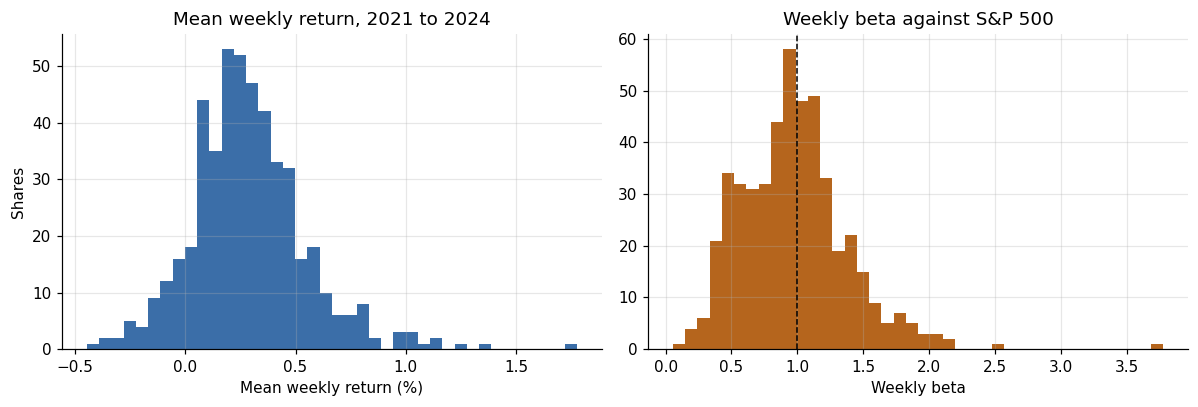

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(rr["mean_weekly_return"] * 100, bins=40, color="#3B6EA8")
axes[0].set_xlabel("Mean weekly return (%)"); axes[0].set_ylabel("Shares")
axes[0].set_title("Mean weekly return, 2021 to 2024")
axes[1].hist(rr["weekly_beta"], bins=40, color="#B5651D")
axes[1].axvline(1, color="black", lw=1, ls="--")
axes[1].set_xlabel("Weekly beta"); axes[1].set_title("Weekly beta against S&P 500")
fig.tight_layout(); save_fig(fig, "fig_1_3_return_beta_distributions"); plt.show()

## 1.4 Adapted RFM

**Observation date:** the final common completed trading date (from 1.2.6). **Window:** Frequency and Monetary use the latest 60 trading sessions ending on the observation date.

**High volume day:** volume greater than twice the mean volume of the preceding 20 trading sessions, excluding the day being tested. The threshold is rolled separately for every share and day. It is implemented as `volume x 20 > 2 x (sum of the previous 20 volumes)`, which is mathematically identical to comparing with twice the mean but uses exact integer arithmetic, so a day exactly equal to the threshold is never misclassified by rounding. A day with fewer than 20 preceding sessions cannot be tested and is never flagged.

* **Recency (R):** calendar days from the latest high volume day anywhere in the valid history to the observation date (weekends and holidays included; an event on the observation date gives 0; no event gives a missing value).
* **Frequency (F):** number of high volume days within the latest 60 sessions (days, not trades or shares).
* **Monetary (M):** sum of Close x Volume over the latest 60 sessions, in USD (approximate traded value; Yahoo `Close` and `Volume` are both split adjusted, so the product is consistent across splits, see 1.2.5).

In [62]:
prev_sum = vol.shift(1).rolling(20, min_periods=20).sum()
testable = prev_sum.notna()
threshold = 2 * prev_sum / 20
event = (vol * 20 > 2 * prev_sum) & testable

WINDOW = vol.index[-60:]
assert WINDOW[-1] == OBS_DATE, "Window must end on the observation date"
assert testable.loc[WINDOW].all().all(), "Every day in the 60 session window needs a full 20 session baseline"
print("60 session window:", WINDOW[0].date(), "to", WINDOW[-1].date())
print("First testable day:", testable.all(axis=1).idxmax().date(), "(day 21 of the history)")

F = event.loc[WINDOW].sum().astype(int)
M = (close.loc[WINDOW] * vol.loc[WINDOW]).sum()
last_event = event.apply(lambda s: s[s].index.max() if s.any() else pd.NaT)
R = (OBS_DATE - last_event).dt.days

rfm = pd.DataFrame({"R_days": R, "F_days": F, "M_usd": M, "last_event_date": last_event})
rfm.describe().T

60 session window: 2024-10-07 to 2024-12-31
First testable day: 2021-02-02 (day 21 of the history)


,count,mean,min,25%,50%,75%,max,std
R_days,485.0,20.393814,4.0,11.0,11.0,14.0,222.0,21.362369
F_days,485.0,2.985567,0.0,2.0,3.0,4.0,8.0,1.32903
M_usd,485.0,39455667903.384956,1297482617.047882,10176788895.426178,16709045815.698242,32365099487.779617,1847697379221.842773,129267180956.0336
last_event_date,485,2024-12-10 14:32:54.432989952,2024-05-23 00:00:00,2024-12-17 00:00:00,2024-12-20 00:00:00,2024-12-20 00:00:00,2024-12-27 00:00:00,NaN


### 1.4.4 Independent verification of R, F and M

R, F and M are recomputed for every share with a plain Python loop that does not use pandas rolling windows, and compared with the vectorised results above. This also confirms there is no look ahead: the loop only ever uses volumes strictly before the day being tested.

In [63]:
dates = list(vol.index)
w0 = len(dates) - 60
mismatch = []
for t in vol.columns:
    v = vol[t].tolist(); c = close[t].tolist()
    flags = [False] * len(v)
    for i in range(20, len(v)):
        flags[i] = v[i] * 20 > 2 * sum(v[i - 20:i])
    f_loop = sum(flags[w0:])
    m_loop = sum(c[i] * v[i] for i in range(w0, len(v)))
    ev = [dates[i] for i in range(len(v)) if flags[i]]
    r_loop = (OBS_DATE - ev[-1]).days if ev else None
    r_vec = None if pd.isna(R[t]) else int(R[t])
    if f_loop != F[t] or r_loop != r_vec or not np.isclose(m_loop, M[t], rtol=0.000000001):
        mismatch.append(t)
assert not mismatch, f"Mismatches: {mismatch}"
print(f"Independent loop check passed for all {vol.shape[1]} shares (R, F and M identical).")

edge = pd.Series({
    "shares": len(rfm),
    "event on observation date (R = 0)": int((rfm["R_days"] == 0).sum()),
    "no qualifying event in history (R missing)": int(rfm["R_days"].isna().sum()),
    "events exist but none in last 60 sessions (F = 0)": int(((rfm["F_days"] == 0) & rfm["R_days"].notna()).sum()),
    "max F": int(rfm["F_days"].max()),
    "max R (days)": rfm["R_days"].max(),
}).to_frame("count")
save_table(edge, "table_1_4_rfm_edge_cases")

Independent loop check passed for all 485 shares (R, F and M identical).


,count
shares,485
event on observation date (R = 0),0
no qualifying event in history (R missing),0
events exist but none in last 60 sessions (F = 0),10
max F,8
max R (days),222


### 1.4.5 Worked example

One share traced by hand: the latest qualifying event (Recency), every qualifying day in the window (Frequency), and the traded value sum (Monetary).

In [64]:
ex = "AAPL" if "AAPL" in vol.columns else rfm["F_days"].idxmax()
exd = pd.DataFrame({"close": close[ex], "volume": vol[ex], "prev20_mean": prev_sum[ex] / 20,
                    "threshold_2x": threshold[ex], "high_volume_day": event[ex]})
exd["ratio_to_threshold"] = exd["volume"] / exd["threshold_2x"]

print(f"Worked example: {ex}")
print(f"Observation date: {OBS_DATE.date()}")
le = rfm.loc[ex, "last_event_date"]
if pd.notna(le):
    row = exd.loc[le]
    print(f"Recency: latest event {le.date()}, volume {row.volume:,.0f} > threshold {row.threshold_2x:,.0f}"
          f" (2 x preceding 20 session mean {row.prev20_mean:,.0f})")
    print(f"         R = {OBS_DATE.date()} minus {le.date()} = {int(rfm.loc[ex, 'R_days'])} calendar days")
else:
    print("Recency: no qualifying event, R is missing and the share is excluded from RFM clustering")

win = exd.loc[WINDOW]
qual = win[win["high_volume_day"]]
print(f"Frequency: {len(qual)} qualifying days in the 60 sessions {WINDOW[0].date()} to {WINDOW[-1].date()}")
near = win[~win["high_volume_day"]]["ratio_to_threshold"].idxmax()
print(f"           closest non qualifying day {near.date()}: volume {win.loc[near, 'volume']:,.0f}"
      f" vs threshold {win.loc[near, 'threshold_2x']:,.0f}")
traded = win["close"] * win["volume"]
print(f"Monetary: sum of 60 daily Close x Volume = ${traded.sum():,.0f}  (${traded.sum() / 1e9:,.2f} bn)")
print(f"          e.g. {WINDOW[-1].date()}: ${win['close'].iloc[-1]:,.2f} x {win['volume'].iloc[-1]:,.0f}"
      f" = ${traded.iloc[-1]:,.0f}")

worked_rfm = pd.concat([qual.assign(note="qualifying day in window"),
                        win.loc[[near]].assign(note="closest non qualifying day")])
worked_rfm = worked_rfm[["close", "volume", "prev20_mean", "threshold_2x", "ratio_to_threshold", "high_volume_day", "note"]]
save_table(worked_rfm.round(2), "table_1_4_worked_rfm_example")

Worked example: AAPL
Observation date: 2024-12-31
Recency: latest event 2024-12-20, volume 147,495,300 > threshold 90,009,210 (2 x preceding 20 session mean 45,004,605)
         R = 2024-12-31 minus 2024-12-20 = 11 calendar days
Frequency: 2 qualifying days in the 60 sessions 2024-10-07 to 2024-12-31
           closest non qualifying day 2024-10-31: volume 64,370,100 vs threshold 77,020,030
Monetary: sum of 60 daily Close x Volume = $623,303,377,707  ($623.30 bn)
          e.g. 2024-12-31: $250.42 x 39,480,700 = $9,886,756,822


,close,volume,prev20_mean,threshold_2x,ratio_to_threshold,high_volume_day,note
Date,,,,,,,
2024-11-25,232.87,90152800.0,43820740.0,87641480.0,1.03,True,qualifying day in window
2024-12-20,254.49,147495300.0,45004605.0,90009210.0,1.64,True,qualifying day in window
2024-10-31,225.91,64370100.0,38510015.0,77020030.0,0.84,False,closest non qualifying day


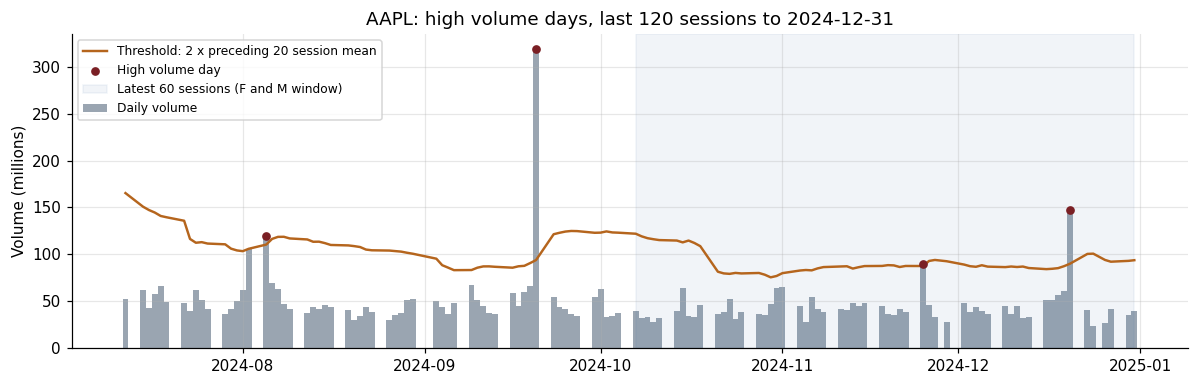

In [65]:
fig, ax = plt.subplots(figsize=(11, 3.6))
span = exd.iloc[-120:]
ax.bar(span.index, span["volume"] / 1e6, color="#9AA5B1", width=1, label="Daily volume")
ax.plot(span.index, span["threshold_2x"] / 1e6, color="#B5651D", lw=1.6, label="Threshold: 2 x preceding 20 session mean")
hits = span[span["high_volume_day"]]
ax.scatter(hits.index, hits["volume"] / 1e6, color="#7A1F24", zorder=3, s=22, label="High volume day")
ax.axvspan(WINDOW[0], WINDOW[-1], color="#3B6EA8", alpha=0.07, label="Latest 60 sessions (F and M window)")
ax.set_ylabel("Volume (millions)"); ax.set_title(f"{ex}: high volume days, last 120 sessions to {OBS_DATE.date()}")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout(); save_fig(fig, "fig_1_4_worked_example_volume_events"); plt.show()

## 1.5 Feature table, summaries and common share set

One row per included share. Shares with no qualifying high volume event have a missing Recency and are excluded from RFM clustering. To compare clustering solutions fairly, **all four baseline solutions use the same common share set**: shares with all five features present.

In [66]:
meta = log.set_index("yf_symbol")[["Symbol", "Security", "GICS Sector"]]
features = rr.join(rfm).join(meta, how="left")
features.index.name = "yf_symbol"
features = features[["Symbol", "Security", "GICS Sector", "n_weeks", "mean_weekly_return", "weekly_beta",
                     "beta_se", "r_squared", "R_days", "F_days", "M_usd", "last_event_date"]]
features.to_csv(os.path.join(DATA_DIR, "feature_table.csv"))
save_table(features, "table_1_5_feature_table_all_shares")

common = features.dropna(subset=["mean_weekly_return", "weekly_beta", "R_days", "F_days", "M_usd"]).copy()
rfm_excluded = features.index.difference(common.index)
print("Included shares:", len(features), "| common share set for clustering:", len(common),
      "| excluded from clustering (no high volume event):", len(rfm_excluded))
if len(rfm_excluded):
    display(features.loc[rfm_excluded, ["Symbol", "Security", "GICS Sector"]])

FEATS = ["mean_weekly_return", "weekly_beta", "R_days", "F_days", "M_usd"]
summary = common[FEATS].describe(percentiles=[0.25, 0.5, 0.75]).T
summary["skew"] = common[FEATS].apply(lambda s: skew(s))
summary.loc["M_usd", ["mean", "std", "min", "25%", "50%", "75%", "max"]] /= 1e9
summary = summary.rename(index={"M_usd": "M_usd (billions)", "mean_weekly_return": "mean_weekly_return (decimal)"})
save_table(summary.round(4), "table_1_5_feature_summary")

Included shares: 485 | common share set for clustering: 485 | excluded from clustering (no high volume event): 0


,count,mean,std,min,25%,50%,75%,max,skew
mean_weekly_return (decimal),485.0,0.0029,0.0026,-0.0045,0.0012,0.0026,0.0042,0.0178,0.8774
weekly_beta,485.0,0.9720,0.4059,0.0555,0.6666,0.9480,1.1792,3.7786,1.1082
R_days,485.0,20.3938,21.3624,4.0000,11.0000,11.0000,14.0000,222.0000,3.6337
F_days,485.0,2.9856,1.3290,0.0000,2.0000,3.0000,4.0000,8.0000,0.4282
M_usd (billions),485.0,39.4557,129.2672,1.2975,10.1768,16.7090,32.3651,1847.6974,11.6359


# Task 2 Stock segmentation and sensitivity analysis

## 2.1 Feature preparation

Two separate matrices on the common share set:

* **Risk and return:** mean weekly return, weekly beta.
* **Trading activity:** R, F, log1p(M).

`log1p` is applied to M as required (traded value spans several orders of magnitude, so without it a handful of mega caps would dominate every distance). Each matrix is then standardised separately (mean 0, standard deviation 1), so every feature carries equal scale in the Euclidean distances used by Ward and K means.

The table below shows skew and outliers before and after transformation. Outliers are retained: they are genuine shares, not data errors (those were removed in 1.2), and removing them would break the common share set. Their influence is discussed as a limitation: Ward and K means both minimise squared distances, so extreme points pull centroids and can form small clusters of their own.

,skew,excess_kurtosis,outliers_abs_z_above_3,outliers_beyond_1_5_IQR
mean_weekly_return,0.877,3.014,6.0,15.0
weekly_beta,1.108,4.511,2.0,10.0
R_days,3.634,20.746,11.0,118.0
F_days,0.428,0.548,5.0,2.0
M_usd,11.636,153.588,5.0,45.0
log1p_M,1.073,2.639,7.0,13.0


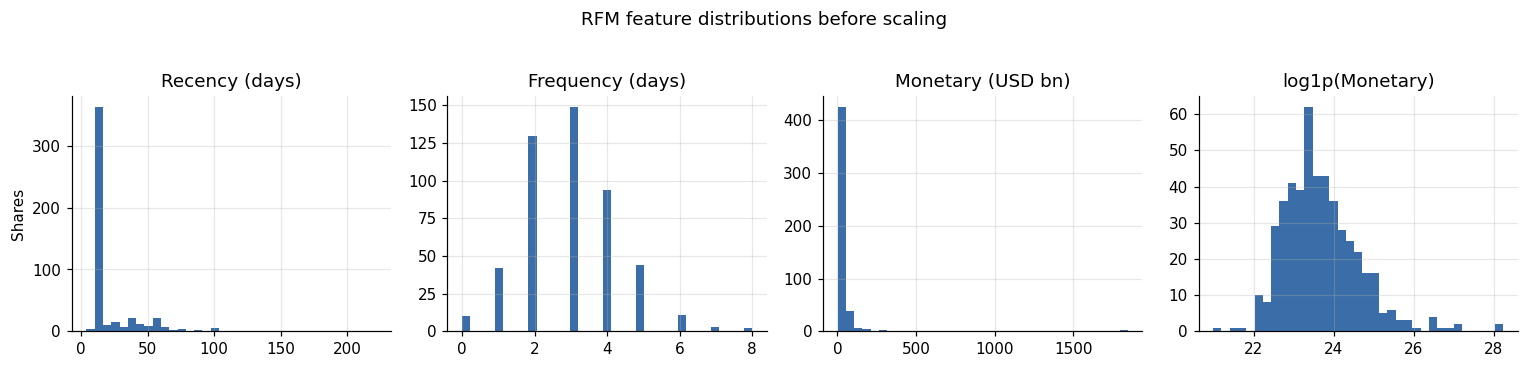

Standardised means: [-0.  0.] [ 0. -0. -0.]
Standardised std:   [1. 1.] [1. 1. 1.]


In [67]:
common["log1p_M"] = np.log1p(common["M_usd"])
RR_COLS = ["mean_weekly_return", "weekly_beta"]
RFM_COLS = ["R_days", "F_days", "log1p_M"]


def outlier_stats(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    z = (s - s.mean()) / s.std()
    return pd.Series({"skew": skew(s), "excess_kurtosis": kurtosis(s),
                      "outliers_abs_z_above_3": int((z.abs() > 3).sum()),
                      "outliers_beyond_1_5_IQR": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())})


prep = pd.DataFrame({c: outlier_stats(common[c]) for c in RR_COLS + ["R_days", "F_days", "M_usd", "log1p_M"]}).T
save_table(prep.round(3), "table_2_1_skew_outliers")
display(prep.round(3))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, c, lab in zip(axes, ["R_days", "F_days", "M_usd", "log1p_M"],
                      ["Recency (days)", "Frequency (days)", "Monetary (USD bn)", "log1p(Monetary)"]):
    vals = common[c] / 1e9 if c == "M_usd" else common[c]
    ax.hist(vals, bins=35, color="#3B6EA8"); ax.set_title(lab)
axes[0].set_ylabel("Shares")
fig.suptitle("RFM feature distributions before scaling", y=1.03)
fig.tight_layout(); save_fig(fig, "fig_2_1_rfm_distributions"); plt.show()

X_rr = StandardScaler().fit_transform(common[RR_COLS])
X_rfm = StandardScaler().fit_transform(common[RFM_COLS])
print("Standardised means:", X_rr.mean(0).round(6), X_rfm.mean(0).round(6))
print("Standardised std:  ", X_rr.std(0).round(6), X_rfm.std(0).round(6))

## 2.2 Agglomerative clustering (Ward) and 2.3 K means

**Ward:** Euclidean distance on standardised features; at each step it merges the two clusters whose union gives the smallest increase in within cluster sum of squares. Suitable here because it produces compact groups comparable to K means and gives a full hierarchy to inspect. Limitations: merges are never undone, it assumes roughly spherical groups of similar size, and it is sensitive to outliers.

**K means:** fixed random seed (`random_state=42`) and 50 initialisations (`n_init=50`), keeping the run with the lowest inertia. Limitations: needs k in advance, assumes spherical groups of similar variance, results depend on initialisation, and extreme points pull centroids.

**Choosing k (2 to 8).** For each k the notebook records the silhouette score, cluster sizes and (for K means) inertia. The suggested k is the one with the highest silhouette among solutions whose smallest cluster holds at least 3% of shares, so a k is not chosen just because it isolates two or three outliers. **The rule is a starting point, not the decision.** On the real data it suggested k = 2 for every model, which only separates high from low. The final values are set in `K_OVERRIDE` below (k = 5 for risk and return, k = 4 for RFM, for both algorithms) and the justification belongs in the report.

In [68]:
MIN_CLUSTER_SHARE = 0.03
# Final choice after reviewing the k scans on the real data (rule suggestion was k = 2 everywhere):
# k = 5 for risk and return and k = 4 for RFM, both algorithms. Set any value to None to use the rule.
K_OVERRIDE = {"ward_rr": 5, "kmeans_rr": 5, "ward_rfm": 4, "kmeans_rfm": 4}


def sizes_str(lab):
    return "/".join(str(x) for x in sorted(np.bincount(lab), reverse=True))


def scan_ward(X):
    rows, labs = [], {}
    for k in K_RANGE:
        lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        labs[k] = lab
        rows.append({"k": k, "silhouette": silhouette_score(X, lab), "smallest": np.bincount(lab).min(), "sizes": sizes_str(lab)})
    return pd.DataFrame(rows).set_index("k"), labs


def scan_kmeans(X):
    rows, labs = [], {}
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
        labs[k] = km.labels_
        rows.append({"k": k, "silhouette": silhouette_score(X, km.labels_), "inertia": km.inertia_,
                     "smallest": np.bincount(km.labels_).min(), "sizes": sizes_str(km.labels_)})
    return pd.DataFrame(rows).set_index("k"), labs


def suggest_k(tab, n):
    ok = tab[tab["smallest"] >= max(5, MIN_CLUSTER_SHARE * n)]
    return int((ok if len(ok) else tab)["silhouette"].idxmax())


def relabel(lab, key):
    # renumber clusters 1..k in ascending order of a key feature, so labels are readable and stable
    order = pd.Series(key).groupby(lab).mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order, start=1)}
    return np.array([mapping[x] for x in lab])


def plot_dendrogram(X, title, name, k_sel):
    Z = linkage(X, method="ward", metric="euclidean")
    fig, ax = plt.subplots(figsize=(11, 4))
    cut = (Z[-k_sel, 2] + Z[-(k_sel - 1), 2]) / 2
    dendrogram(Z, truncate_mode="lastp", p=40, color_threshold=cut, above_threshold_color="#888888",
               show_leaf_counts=True, leaf_rotation=90, leaf_font_size=7, ax=ax)
    ax.axhline(cut, color="#7A1F24", ls="--", lw=1)
    ax.text(ax.get_xlim()[1], cut, f"  cut for k = {k_sel}", va="bottom", ha="right", color="#7A1F24", fontsize=8)
    ax.set_ylabel("Ward merge distance"); ax.set_xlabel("Clusters (leaf labels show number of shares)")
    ax.set_title(title); ax.grid(False)
    fig.tight_layout(); save_fig(fig, name); plt.show()
    heights = pd.DataFrame({"k after merge": range(1, 9), "merge distance": Z[-8:, 2][::-1].round(3)})
    return Z, heights

### 2.2.1 Ward on risk and return

,silhouette,smallest,sizes
k,,,
2,0.3410,92,393/92
3,0.2743,92,229/164/92
4,0.2818,47,182/164/92/47
5,0.3042,47,182/98/92/66/47
6,0.3207,5,182/98/87/66/47/5
7,0.3252,5,160/98/87/66/47/22/5
8,0.3227,5,160/98/66/56/47/31/22/5


Suggested by rule: 2 | selected: 5


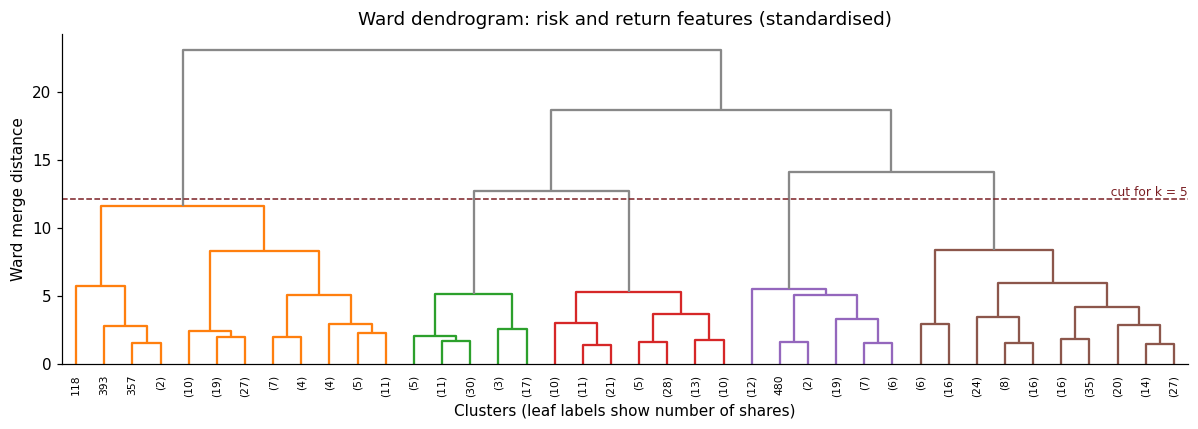

Largest merge distances (big jumps suggest natural cut points):


,k after merge,merge distance
0,1,23.131
1,2,18.718
2,3,14.106
3,4,12.707
4,5,11.638
5,6,8.366
6,7,8.333
7,8,5.949


In [69]:
ward_rr_tab, ward_rr_labs = scan_ward(X_rr)
K_WARD_RR = K_OVERRIDE["ward_rr"] or suggest_k(ward_rr_tab, len(common))
save_table(ward_rr_tab.round(4), "table_2_2_ward_rr_k_scan")
display(ward_rr_tab.round(4))
print("Suggested by rule:", suggest_k(ward_rr_tab, len(common)), "| selected:", K_WARD_RR)
Z_rr, h_rr = plot_dendrogram(X_rr, "Ward dendrogram: risk and return features (standardised)", "fig_2_2_dendrogram_risk_return", K_WARD_RR)
print("Largest merge distances (big jumps suggest natural cut points):")
display(h_rr)

### 2.2.2 Ward on RFM

,silhouette,smallest,sizes
k,,,
2,0.3680,82,403/82
3,0.3040,82,249/154/82
4,0.2885,42,207/154/82/42
5,0.3048,10,207/154/72/42/10
6,0.3141,10,207/136/72/42/18/10
7,0.2916,10,141/136/72/66/42/18/10
8,0.3020,10,141/79/72/66/57/42/18/10


Suggested by rule: 2 | selected: 4


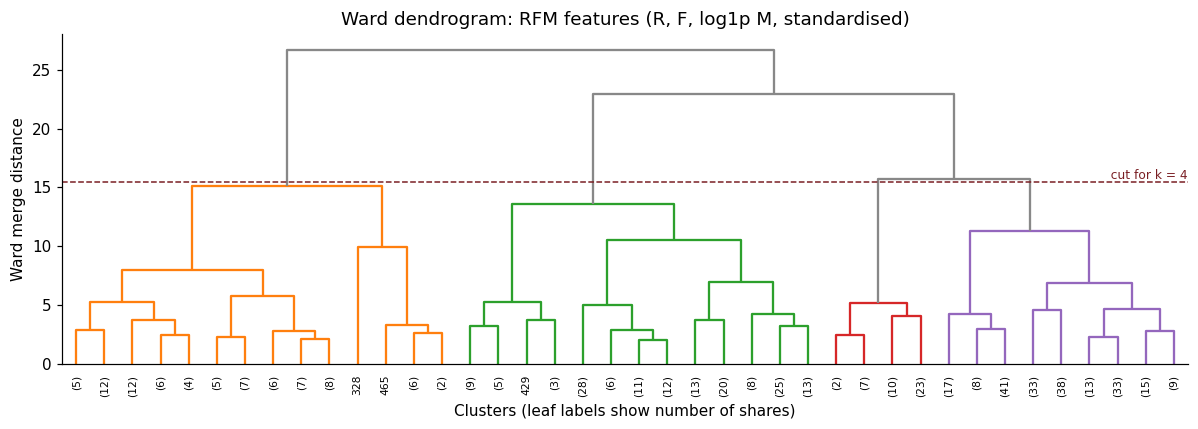

,k after merge,merge distance
0,1,26.687
1,2,22.953
2,3,15.748
3,4,15.146
4,5,13.579
5,6,11.308
6,7,10.550
7,8,9.959


scipy and scikit learn Ward partitions agree.


In [70]:
ward_rfm_tab, ward_rfm_labs = scan_ward(X_rfm)
K_WARD_RFM = K_OVERRIDE["ward_rfm"] or suggest_k(ward_rfm_tab, len(common))
save_table(ward_rfm_tab.round(4), "table_2_2_ward_rfm_k_scan")
display(ward_rfm_tab.round(4))
print("Suggested by rule:", suggest_k(ward_rfm_tab, len(common)), "| selected:", K_WARD_RFM)
Z_rfm, h_rfm = plot_dendrogram(X_rfm, "Ward dendrogram: RFM features (R, F, log1p M, standardised)", "fig_2_2_dendrogram_rfm", K_WARD_RFM)
display(h_rfm)

# Consistency check: scipy and scikit learn Ward give the same partition
for X, Z, k, labs in [(X_rr, Z_rr, K_WARD_RR, ward_rr_labs), (X_rfm, Z_rfm, K_WARD_RFM, ward_rfm_labs)]:
    assert adjusted_rand_score(fcluster(Z, k, "maxclust"), labs[k]) > 0.999
print("scipy and scikit learn Ward partitions agree.")

### 2.3.1 K means on both matrices

Risk and return


,silhouette,inertia,smallest,sizes
k,,,,
2,0.3889,617.0084,143,342/143
3,0.3281,459.7503,120,201/164/120
4,0.3260,370.1759,41,162/148/134/41
5,0.3396,308.2378,29,166/131/109/50/29
6,0.3367,263.4377,5,156/127/106/51/40/5
7,0.3354,225.0821,5,144/81/72/71/62/50/5
8,0.3614,192.6502,5,139/76/75/74/47/40/29/5


RFM


,silhouette,inertia,smallest,sizes
k,,,,
2,0.4231,1064.4038,68,417/68
3,0.3250,794.9105,64,269/152/64
4,0.3405,609.1344,61,212/121/91/61
5,0.3574,514.1200,11,198/121/87/68/11
6,0.3453,436.7588,11,141/119/105/68/41/11
7,0.3472,385.7296,1,141/119/104/68/41/11/1
8,0.3503,341.6286,1,140/105/83/66/64/15/11/1


Suggested by rule: risk and return 2 | RFM 2
Selected k: risk and return 5 | RFM 4


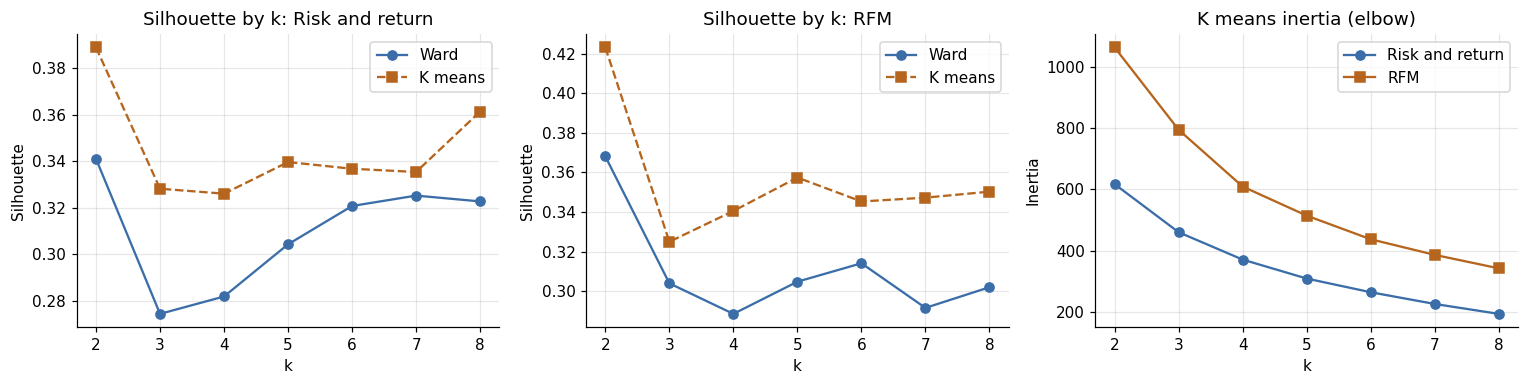

In [71]:
km_rr_tab, km_rr_labs = scan_kmeans(X_rr)
km_rfm_tab, km_rfm_labs = scan_kmeans(X_rfm)
K_KM_RR = K_OVERRIDE["kmeans_rr"] or suggest_k(km_rr_tab, len(common))
K_KM_RFM = K_OVERRIDE["kmeans_rfm"] or suggest_k(km_rfm_tab, len(common))
save_table(km_rr_tab.round(4), "table_2_3_kmeans_rr_k_scan")
save_table(km_rfm_tab.round(4), "table_2_3_kmeans_rfm_k_scan")
print("Risk and return"); display(km_rr_tab.round(4))
print("RFM"); display(km_rfm_tab.round(4))
print("Suggested by rule: risk and return", suggest_k(km_rr_tab, len(common)), "| RFM", suggest_k(km_rfm_tab, len(common)))
print("Selected k: risk and return", K_KM_RR, "| RFM", K_KM_RFM)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (wt, kt, lab) in zip(axes[:2], [(ward_rr_tab, km_rr_tab, "Risk and return"), (ward_rfm_tab, km_rfm_tab, "RFM")]):
    ax.plot(wt.index, wt["silhouette"], "o-", label="Ward", color="#3B6EA8")
    ax.plot(kt.index, kt["silhouette"], "s--", label="K means", color="#B5651D")
    ax.set_title(f"Silhouette by k: {lab}"); ax.set_xlabel("k"); ax.set_ylabel("Silhouette"); ax.legend()
axes[2].plot(km_rr_tab.index, km_rr_tab["inertia"], "o-", label="Risk and return", color="#3B6EA8")
axes[2].plot(km_rfm_tab.index, km_rfm_tab["inertia"], "s-", label="RFM", color="#B5651D")
axes[2].set_title("K means inertia (elbow)"); axes[2].set_xlabel("k"); axes[2].set_ylabel("Inertia"); axes[2].legend()
fig.tight_layout(); save_fig(fig, "fig_2_3_silhouette_inertia"); plt.show()

### 2.3.2 Initialisation stability

K means can converge to different local optima depending on its starting centroids. Each selected model is refitted with 10 different seeds, once with a single initialisation and once with 50, and compared with the reference solution using the adjusted Rand index (1 = identical partition). Multiple initialisations should give values at or near 1.

In [72]:
stab = []
for name, X, k, ref in [("risk and return", X_rr, K_KM_RR, km_rr_labs[K_KM_RR]), ("RFM", X_rfm, K_KM_RFM, km_rfm_labs[K_KM_RFM])]:
    for n_init in (1, 50):
        aris = [adjusted_rand_score(ref, KMeans(n_clusters=k, n_init=n_init, random_state=s).fit_predict(X)) for s in range(10)]
        stab.append({"matrix": name, "k": k, "n_init": n_init, "mean ARI vs reference": np.mean(aris), "min ARI": np.min(aris)})
stab = pd.DataFrame(stab)
save_table(stab.round(4), "table_2_3_kmeans_initialisation_stability", index=False)

,matrix,k,n_init,mean ARI vs reference,min ARI
0,risk and return,5,1,0.6019,0.3277
1,risk and return,5,50,0.9579,0.9024
2,RFM,4,1,0.7838,0.3460
3,RFM,4,50,0.9994,0.9939


## 2.4 Cluster profiles and algorithm comparison

Cluster numbers are arbitrary, so they are renumbered in ascending order of a key feature (weekly beta for risk and return, Frequency for RFM) to make tables readable. Profiles are shown in original units: mean weekly return and its median in percent, beta, R and F in days, M in USD billions (median, because traded value is highly skewed).

In [73]:
common["ward_rr"] = relabel(ward_rr_labs[K_WARD_RR], common["weekly_beta"].values)
common["kmeans_rr"] = relabel(km_rr_labs[K_KM_RR], common["weekly_beta"].values)
common["ward_rfm"] = relabel(ward_rfm_labs[K_WARD_RFM], common["F_days"].values)
common["kmeans_rfm"] = relabel(km_rfm_labs[K_KM_RFM], common["F_days"].values)


def profile(df, col):
    g = df.groupby(col)
    return pd.DataFrame({
        "shares": g.size(),
        "mean weekly return %": g["mean_weekly_return"].mean() * 100,
        "median weekly return %": g["mean_weekly_return"].median() * 100,
        "mean beta": g["weekly_beta"].mean(),
        "median beta": g["weekly_beta"].median(),
        "mean R days": g["R_days"].mean(),
        "median R days": g["R_days"].median(),
        "mean F days": g["F_days"].mean(),
        "median M USD bn": g["M_usd"].median() / 1e9,
        "mean r squared": g["r_squared"].mean(),
    }).round(3)


profiles = {}
for col in ["ward_rr", "kmeans_rr", "ward_rfm", "kmeans_rfm"]:
    profiles[col] = save_table(profile(common, col), f"table_2_4_profile_{col}")
    print(col); display(profiles[col])

ward_rr


,shares,mean weekly return %,median weekly return %,mean beta,median beta,mean R days,median R days,mean F days,median M USD bn,mean r squared
ward_rr,,,,,,,,,,
1,66,0.088,0.113,0.439,0.449,26.197,11.0,2.894,17.701,0.110
2,98,0.422,0.392,0.710,0.666,16.908,11.0,2.704,17.649,0.219
3,182,0.132,0.166,0.973,0.964,17.714,11.0,3.011,12.985,0.315
4,92,0.632,0.550,1.298,1.218,23.674,11.0,3.196,24.184,0.347
5,47,0.209,0.253,1.624,1.509,23.468,11.0,3.191,28.918,0.376


kmeans_rr


,shares,mean weekly return %,median weekly return %,mean beta,median beta,mean R days,median R days,mean F days,median M USD bn,mean r squared
kmeans_rr,,,,,,,,,,
1,131,0.191,0.195,0.537,0.534,22.489,11.0,3.000,15.044,0.159
2,166,0.426,0.415,0.979,0.985,16.880,11.0,2.898,18.112,0.316
3,109,0.038,0.076,1.037,1.036,19.092,11.0,3.000,13.330,0.317
4,29,0.914,0.815,1.531,1.447,29.517,11.0,3.172,25.749,0.308
5,50,0.254,0.270,1.622,1.525,24.120,11.0,3.100,32.859,0.379


ward_rfm


,shares,mean weekly return %,median weekly return %,mean beta,median beta,mean R days,median R days,mean F days,median M USD bn,mean r squared
ward_rfm,,,,,,,,,,
1,82,0.286,0.244,1.009,1.047,58.305,54.5,2.098,17.849,0.255
2,154,0.338,0.325,1.010,0.989,13.682,11.0,2.864,39.695,0.288
3,207,0.247,0.244,0.926,0.924,11.140,11.0,2.942,10.785,0.283
4,42,0.294,0.280,0.989,1.004,16.595,11.0,5.381,14.412,0.279


kmeans_rfm


,shares,mean weekly return %,median weekly return %,mean beta,median beta,mean R days,median R days,mean F days,median M USD bn,mean r squared
kmeans_rfm,,,,,,,,,,
1,61,0.300,0.253,0.975,1.051,66.016,55.0,1.672,21.242,0.261
2,212,0.275,0.259,0.939,0.931,13.264,11.0,2.368,13.336,0.287
3,91,0.341,0.295,1.064,1.048,15.143,11.0,3.231,60.183,0.286
4,121,0.261,0.254,0.959,0.919,13.835,11.0,4.545,12.786,0.272


In [74]:
agree = pd.DataFrame([
    {"matrix": "risk and return", "Ward k": K_WARD_RR, "K means k": K_KM_RR,
     "ARI Ward vs K means": adjusted_rand_score(common["ward_rr"], common["kmeans_rr"])},
    {"matrix": "RFM", "Ward k": K_WARD_RFM, "K means k": K_KM_RFM,
     "ARI Ward vs K means": adjusted_rand_score(common["ward_rfm"], common["kmeans_rfm"])},
])
save_table(agree.round(4), "table_2_4_algorithm_agreement", index=False)
display(agree.round(4))

ct_rr = save_table(pd.crosstab(common["ward_rr"], common["kmeans_rr"], rownames=["Ward"], colnames=["K means"]), "table_2_4_crosstab_rr")
ct_rfm = save_table(pd.crosstab(common["ward_rfm"], common["kmeans_rfm"], rownames=["Ward"], colnames=["K means"]), "table_2_4_crosstab_rfm")
print("Risk and return: Ward rows vs K means columns"); display(ct_rr)
print("RFM: Ward rows vs K means columns"); display(ct_rfm)

,matrix,Ward k,K means k,ARI Ward vs K means
0,risk and return,5,5,0.3201
1,RFM,4,4,0.3425


Risk and return: Ward rows vs K means columns


K means,1,2,3,4,5
Ward,,,,,
1,63,0,3,0,0
2,36,62,0,0,0
3,32,47,103,0,0
4,0,57,0,29,6
5,0,0,3,0,44


RFM: Ward rows vs K means columns


K means,1,2,3,4
Ward,,,,
1,57,14,7,4
2,4,52,84,14
3,0,146,0,61
4,0,0,0,42


**Visualisations.** The risk and return matrix has only two features, so it is plotted directly with no dimensionality reduction. The RFM matrix has three, so it is projected onto its first two principal components (PCA on the standardised features). PCA is used only for display: clusters were fitted on all three features, so points that overlap in the plot may be well separated in the third dimension. The explained variance and loadings show what each axis means.

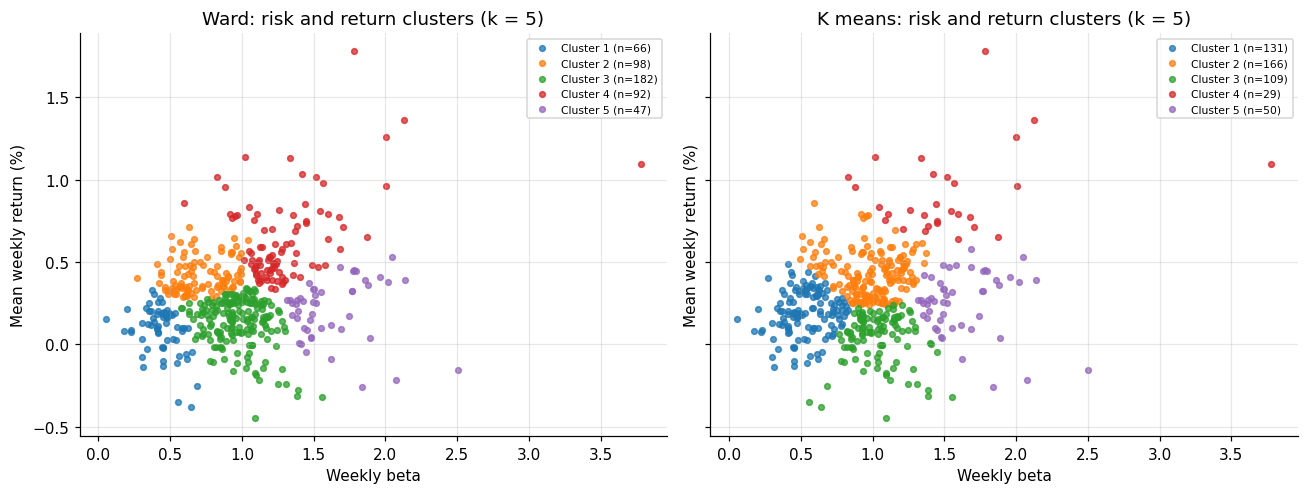

PCA explained variance: PC1 45.8%, PC2 33.7%, total 79.5%


,PC1,PC2
R,0.712,0.025
F,-0.650,0.401
log1p M,0.266,0.916


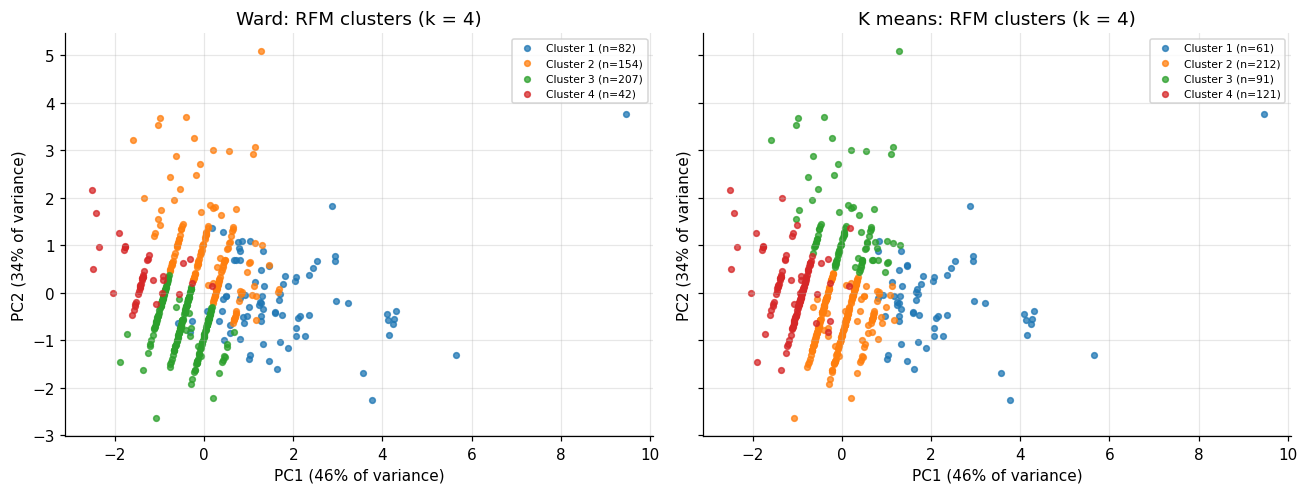

In [75]:
cmap = plt.get_cmap("tab10")


def scatter_clusters(ax, x, y, lab, title, xl, yl):
    for i, c in enumerate(sorted(np.unique(lab))):
        m = lab == c
        ax.scatter(x[m], y[m], s=14, alpha=0.75, color=cmap(i), label=f"Cluster {c} (n={m.sum()})")
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=7, loc="best")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, col, nm in zip(axes, ["ward_rr", "kmeans_rr"], ["Ward", "K means"]):
    scatter_clusters(ax, common["weekly_beta"].values, common["mean_weekly_return"].values * 100, common[col].values,
                     f"{nm}: risk and return clusters (k = {common[col].nunique()})", "Weekly beta", "Mean weekly return (%)")
fig.tight_layout(); save_fig(fig, "fig_2_4_risk_return_clusters"); plt.show()

pca = PCA(n_components=2, random_state=SEED).fit(X_rfm)
P = pca.transform(X_rfm)
ev = pca.explained_variance_ratio_
loadings = save_table(pd.DataFrame(pca.components_.T, index=["R", "F", "log1p M"], columns=["PC1", "PC2"]).round(3), "table_2_4_pca_loadings")
print(f"PCA explained variance: PC1 {ev[0]:.1%}, PC2 {ev[1]:.1%}, total {ev.sum():.1%}")
display(loadings)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, col, nm in zip(axes, ["ward_rfm", "kmeans_rfm"], ["Ward", "K means"]):
    scatter_clusters(ax, P[:, 0], P[:, 1], common[col].values, f"{nm}: RFM clusters (k = {common[col].nunique()})",
                     f"PC1 ({ev[0]:.0%} of variance)", f"PC2 ({ev[1]:.0%} of variance)")
fig.tight_layout(); save_fig(fig, "fig_2_4_rfm_clusters_pca"); plt.show()

## 2.5 RFM sensitivity and correlated inputs

### 2.5.1 Correlation among R, F and log1p(M)

Pearson (linear) and Spearman (rank) correlations on the common share set. If two inputs are strongly correlated they partly measure the same thing, so standardising each one to unit variance still lets that shared dimension count roughly twice in the Euclidean distance. A correlation alone does not prove that a feature dominates the clustering; 2.5.2 tests that directly.

Pearson


,R,F,log1p M
R,1.000,-0.348,0.153
F,-0.348,1.000,0.014
log1p M,0.153,0.014,1.000


Spearman


,R,F,log1p M
R,1.000,-0.201,0.138
F,-0.201,1.000,-0.047
log1p M,0.138,-0.047,1.000


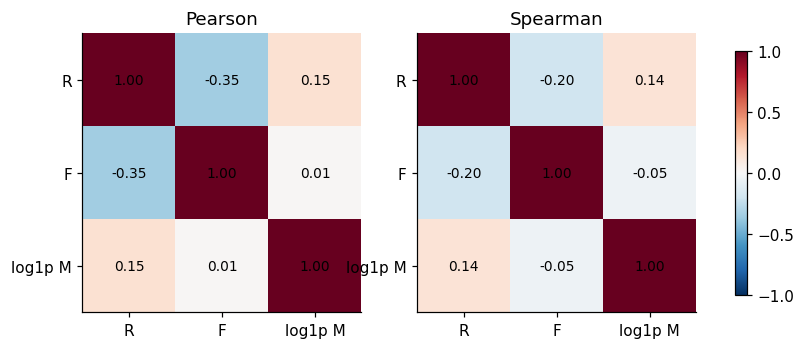

In [76]:
rfm_in = common[RFM_COLS].rename(columns={"R_days": "R", "F_days": "F", "log1p_M": "log1p M"})
corr_p = save_table(rfm_in.corr(method="pearson").round(3), "table_2_5_correlation_pearson")
corr_s = save_table(rfm_in.corr(method="spearman").round(3), "table_2_5_correlation_spearman")
print("Pearson"); display(corr_p)
print("Spearman"); display(corr_s)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, cm, nm in zip(axes, [corr_p, corr_s], ["Pearson", "Spearman"]):
    im = ax.imshow(cm.values, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(3)); ax.set_xticklabels(cm.columns); ax.set_yticks(range(3)); ax.set_yticklabels(cm.index)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(nm); ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8)
save_fig(fig, "fig_2_5_rfm_correlations"); plt.show()

### 2.5.2 Removal of Monetary

The selected Ward RFM solution is refitted using R and F only, with the same shares and the same k. The reduced matrix is standardised afresh. Memberships are compared with the adjusted Rand index, which ignores arbitrary cluster numbering (1 = identical, around 0 = no more agreement than chance).

To see what M contributes, each solution's clusters are profiled on traded value, and the share of each feature's variance explained by cluster membership (eta squared, between cluster sum of squares / total) is compared. If removing M changes memberships substantially and the full solution's clusters differ mainly in traded value, M is mainly separating liquidity levels rather than activity.

In [77]:
RF_COLS = ["R_days", "F_days"]
X_rf = StandardScaler().fit_transform(common[RF_COLS])
lab_rf = AgglomerativeClustering(n_clusters=K_WARD_RFM, linkage="ward").fit_predict(X_rf)
common["ward_rf_only"] = relabel(lab_rf, common["F_days"].values)

ari_m = adjusted_rand_score(common["ward_rfm"], common["ward_rf_only"])
print(f"Ward RFM (R, F, log1p M) vs Ward R and F only, k = {K_WARD_RFM}: adjusted Rand index = {ari_m:.3f}")
print("Silhouette, R and F only:", round(silhouette_score(X_rf, lab_rf), 4))

ct_m = save_table(pd.crosstab(common["ward_rfm"], common["ward_rf_only"], rownames=["with M"], colnames=["without M"]), "table_2_5_crosstab_monetary_removal")
display(ct_m)


def traded_profile(col):
    g = common.groupby(col)
    return pd.DataFrame({"shares": g.size(), "median M USD bn": g["M_usd"].median() / 1e9,
                         "mean log1p M": g["log1p_M"].mean(), "mean F days": g["F_days"].mean(),
                         "median R days": g["R_days"].median()}).round(3)


tp_full = save_table(traded_profile("ward_rfm"), "table_2_5_traded_value_with_M")
tp_rf = save_table(traded_profile("ward_rf_only"), "table_2_5_traded_value_without_M")
print("Clusters with M"); display(tp_full)
print("Clusters without M"); display(tp_rf)


def eta_sq(values, lab):
    v = pd.Series(values); total = ((v - v.mean()) ** 2).sum()
    between = v.groupby(lab).apply(lambda s: len(s) * (s.mean() - v.mean()) ** 2).sum()
    return between / total


eta = pd.DataFrame({sol: {f: eta_sq(common[f].values, common[sol].values) for f in RFM_COLS}
                    for sol in ["ward_rfm", "ward_rf_only"]}).rename(columns={"ward_rfm": "with M", "ward_rf_only": "without M"})
eta.index = ["R", "F", "log1p M"]
save_table(eta.round(3), "table_2_5_eta_squared")
print("Share of each feature's variance explained by cluster membership (eta squared)")
display(eta.round(3))

Ward RFM (R, F, log1p M) vs Ward R and F only, k = 4: adjusted Rand index = 0.203
Silhouette, R and F only: 0.5167


without M,1,2,3,4
with M,,,,
1,10,0,69,3
2,0,59,9,86
3,0,66,0,141
4,0,0,1,41


Clusters with M


,shares,median M USD bn,mean log1p M,mean F days,median R days
ward_rfm,,,,,
1,82,17.849,23.749,2.098,54.5
2,154,39.695,24.613,2.864,11.0
3,207,10.785,23.033,2.942,11.0
4,42,14.412,23.347,5.381,11.0


Clusters without M


,shares,median M USD bn,mean log1p M,mean F days,median R days
ward_rf_only,,,,,
1,10,23.786,23.985,0.000,102.0
2,125,17.699,23.687,1.800,11.0
3,79,20.132,23.780,2.266,49.0
4,271,14.926,23.641,3.852,11.0


Share of each feature's variance explained by cluster membership (eta squared)


,with M,without M
R,0.648,0.832
F,0.361,0.596
log1p M,0.524,0.005


# Task 3 evidence: profiles, sector composition and limitations

### 3.2.1 Comparing risk and return clusters with RFM clusters

Do the two segmentations describe the same shares? The adjusted Rand index between them and their cross tabulation show whether trading activity groups line up with risk groups. Sector composition shows which industries dominate each cluster; Cramer's V (0 = no association, 1 = perfect) summarises how strongly cluster membership is tied to sector.

In [78]:
ari_rr_rfm = adjusted_rand_score(common["ward_rr"], common["ward_rfm"])
print(f"Ward risk and return vs Ward RFM: adjusted Rand index = {ari_rr_rfm:.3f}")
ct_rr_rfm = save_table(pd.crosstab(common["ward_rr"], common["ward_rfm"], rownames=["risk and return"], colnames=["RFM"]), "table_3_2_crosstab_rr_vs_rfm")
display(ct_rr_rfm)


def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))


sector_stats = []
for col, nm in [("ward_rr", "Ward risk and return"), ("ward_rfm", "Ward RFM"), ("kmeans_rr", "K means risk and return"), ("kmeans_rfm", "K means RFM")]:
    sector_stats.append({"solution": nm, "Cramer's V with sector": cramers_v(common[col], common["GICS Sector"])})
sector_stats = save_table(pd.DataFrame(sector_stats).round(3), "table_3_2_sector_association", index=False)
display(sector_stats)

Ward risk and return vs Ward RFM: adjusted Rand index = 0.039


RFM,1,2,3,4
risk and return,,,,
1,16,23,23,4
2,10,35,47,6
3,28,39,100,15
4,19,37,24,12
5,9,20,13,5


,solution,Cramer's V with sector
0,Ward risk and return,0.426
1,Ward RFM,0.236
2,K means risk and return,0.374
3,K means RFM,0.233


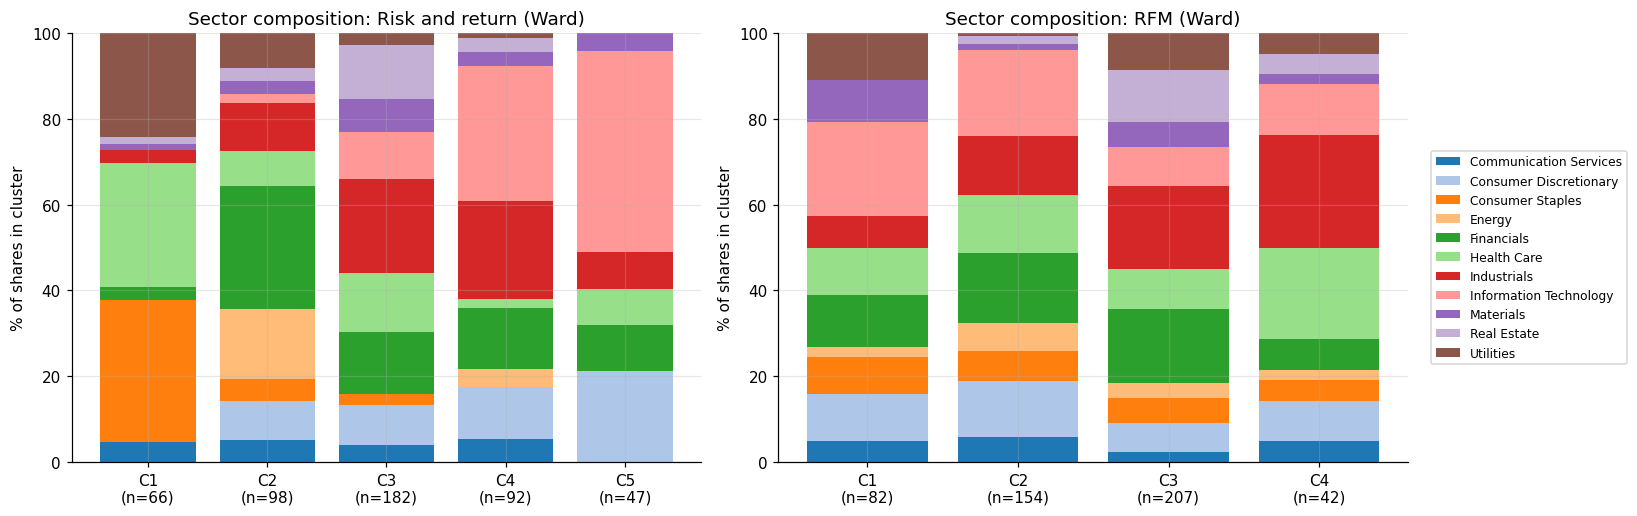

,% of common share set
GICS Sector,
Industrials,16.1
Financials,15.3
Information Technology,15.1
Health Care,12.0
Consumer Discretionary,9.7
Consumer Staples,6.6
Utilities,6.2
Real Estate,6.2
Materials,4.7


In [79]:
sectors = sorted(common["GICS Sector"].dropna().unique())
scol = {s: plt.get_cmap("tab20")(i) for i, s in enumerate(sectors)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col, nm in zip(axes, ["ward_rr", "ward_rfm"], ["Risk and return (Ward)", "RFM (Ward)"]):
    comp = pd.crosstab(common[col], common["GICS Sector"], normalize="index") * 100
    counts = pd.crosstab(common[col], common["GICS Sector"])
    save_table(counts, f"table_3_2_sector_counts_{col}")
    save_table(comp.round(1), f"table_3_2_sector_percent_{col}")
    bottom = np.zeros(len(comp))
    for s in comp.columns:
        ax.bar([f"C{c}\n(n={counts.loc[c].sum()})" for c in comp.index], comp[s].values, bottom=bottom, color=scol[s], label=s)
        bottom += comp[s].values
    ax.set_ylabel("% of shares in cluster"); ax.set_title(f"Sector composition: {nm}"); ax.set_ylim(0, 100)
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8)
fig.tight_layout(); save_fig(fig, "fig_3_2_sector_composition"); plt.show()

overall = (common["GICS Sector"].value_counts(normalize=True) * 100).round(1).to_frame("% of common share set")
save_table(overall, "table_3_2_sector_overall")

### 3.2.3 Return dependencies: does a beta cluster imply diversification?

Beta measures each share's sensitivity to the index, not how shares move with each other. The average pairwise correlation of weekly returns, within each risk and return cluster and across the whole set, shows how strongly shares co move. High within cluster correlation means picking several shares from one "low beta" cluster does not reduce risk as much as the beta values alone might suggest. Shares from different clusters can also remain highly correlated.

In [80]:
R_w = weekly_ret[common.index]
C = R_w.corr().values
iu = np.triu_indices_from(C, k=1)
dep = [{"group": "all shares", "shares": len(common), "mean pairwise correlation": C[iu].mean()}]
for c in sorted(common["ward_rr"].unique()):
    idx = np.where(common["ward_rr"].values == c)[0]
    if len(idx) > 1:
        sub = C[np.ix_(idx, idx)]
        dep.append({"group": f"risk and return cluster {c}", "shares": len(idx),
                    "mean pairwise correlation": sub[np.triu_indices_from(sub, k=1)].mean()})
lab = common["ward_rr"].values
between = C[iu][lab[iu[0]] != lab[iu[1]]]
dep.append({"group": "pairs in different clusters", "shares": None, "mean pairwise correlation": between.mean()})
dep = save_table(pd.DataFrame(dep).round(3), "table_3_2_return_dependencies", index=False)
display(dep)

mc = [t for t in multi_class["Symbol"].str.replace(".", "-", regex=False) if t in R_w.columns]
if len(mc) >= 2:
    print("Weekly return correlation between share classes of the same company:")
    display(R_w[mc].corr().round(3))

,group,shares,mean pairwise correlation
0,all shares,485.0,0.300
1,risk and return cluster 1,66.0,0.312
2,risk and return cluster 2,98.0,0.325
3,risk and return cluster 3,182.0,0.367
4,risk and return cluster 4,92.0,0.374
5,risk and return cluster 5,47.0,0.439
6,pairs in different clusters,NaN,0.281


Weekly return correlation between share classes of the same company:


Ticker,NWS,NWSA,GOOGL,GOOG,FOX,FOXA
Ticker,,,,,,
NWS,1.000,0.981,0.353,0.350,0.463,0.439
NWSA,0.981,1.000,0.365,0.362,0.472,0.447
GOOGL,0.353,0.365,1.000,0.996,0.071,0.049
GOOG,0.350,0.362,0.996,1.000,0.074,0.052
FOX,0.463,0.472,0.071,0.074,1.000,0.992
FOXA,0.439,0.447,0.049,0.052,0.992,1.000


## Exports

* `outputs/cluster_assignments.csv`: one row per share in the common set with the four baseline cluster assignments and the R and F only solution.
* `outputs/results_summary.json`: the key numbers quoted in the report.
* `rfm_coursework_outputs.zip`: the `data/` and `outputs/` folders together, for download and upload to GitHub.

In [81]:
assign_cols = ["Symbol", "Security", "GICS Sector", "mean_weekly_return", "weekly_beta", "R_days", "F_days", "M_usd",
               "log1p_M", "ward_rr", "kmeans_rr", "ward_rfm", "kmeans_rfm", "ward_rf_only"]
save_table(common[assign_cols], "cluster_assignments")
common[assign_cols].to_csv(os.path.join(DATA_DIR, "cluster_assignments.csv"))

results = {
    **run_config,
    "aligned_weekly_return_observations": int(N_WEEKS),
    "first_return_week": str(bench_ret.index[0].date()),
    "last_return_week": str(bench_ret.index[-1].date()),
    "rfm_window_start": str(WINDOW[0].date()),
    "rfm_window_end": str(WINDOW[-1].date()),
    "shares_with_features": int(len(features)),
    "common_share_set": int(len(common)),
    "shares_without_high_volume_event": int(len(rfm_excluded)),
    "average_beta": round(float(common["weekly_beta"].mean()), 4),
    "selected_k": {"ward_rr": K_WARD_RR, "kmeans_rr": K_KM_RR, "ward_rfm": K_WARD_RFM, "kmeans_rfm": K_KM_RFM},
    "silhouette_selected": {
        "ward_rr": round(float(ward_rr_tab.loc[K_WARD_RR, "silhouette"]), 4),
        "kmeans_rr": round(float(km_rr_tab.loc[K_KM_RR, "silhouette"]), 4),
        "ward_rfm": round(float(ward_rfm_tab.loc[K_WARD_RFM, "silhouette"]), 4),
        "kmeans_rfm": round(float(km_rfm_tab.loc[K_KM_RFM, "silhouette"]), 4)},
    "ari_ward_vs_kmeans_rr": round(float(agree.iloc[0]["ARI Ward vs K means"]), 4),
    "ari_ward_vs_kmeans_rfm": round(float(agree.iloc[1]["ARI Ward vs K means"]), 4),
    "ari_monetary_removal": round(float(ari_m), 4),
    "ari_rr_vs_rfm": round(float(ari_rr_rfm), 4),
    "pca_explained_variance": [round(float(v), 4) for v in ev],
    "pearson_correlations": corr_p.to_dict(),
    "mean_pairwise_return_correlation": round(float(C[iu].mean()), 4),
    "random_seed": SEED,
    "kmeans_n_init": 50,
}
with open(os.path.join(OUT_DIR, "results_summary.json"), "w") as f:
    json.dump(results, f, indent=2, default=str)

import shutil
pd.Series(versions).to_frame("version").to_csv(os.path.join(OUT_DIR, "package_versions.csv"))
with open("requirements.txt", "w") as f:
    f.write("\n".join([f"pandas=={pd.__version__}", f"numpy=={np.__version__}", f"yfinance=={yf.__version__}",
                        f"scikit_learn=={sklearn.__version__}",
                        f"scipy=={scipy.__version__}", f"matplotlib=={matplotlib.__version__}",
                        f"requests=={requests.__version__}", "pyarrow", "lxml"]) + "\n")
os.makedirs("bundle", exist_ok=True)
for d in ("data", "outputs"):
    shutil.copytree(d, os.path.join("bundle", d), dirs_exist_ok=True)
shutil.copy("requirements.txt", "bundle/requirements.txt")
shutil.make_archive("rfm_coursework_outputs", "zip", "bundle")
print("Saved", len(os.listdir(OUT_DIR)), "files to outputs/ and created rfm_coursework_outputs.zip")
sorted(os.listdir(OUT_DIR))

Saved 47 files to outputs/ and created rfm_coursework_outputs.zip


['cluster_assignments.csv',
 'fig_1_3_return_beta_distributions.png',
 'fig_1_4_worked_example_volume_events.png',
 'fig_2_1_rfm_distributions.png',
 'fig_2_2_dendrogram_rfm.png',
 'fig_2_2_dendrogram_risk_return.png',
 'fig_2_3_silhouette_inertia.png',
 'fig_2_4_rfm_clusters_pca.png',
 'fig_2_4_risk_return_clusters.png',
 'fig_2_5_rfm_correlations.png',
 'fig_3_2_sector_composition.png',
 'package_versions.csv',
 'results_summary.json',
 'table_1_2_exclusion_summary.csv',
 'table_1_3_worked_weekly_returns.csv',
 'table_1_4_rfm_edge_cases.csv',
 'table_1_4_worked_rfm_example.csv',
 'table_1_5_feature_summary.csv',
 'table_1_5_feature_table_all_shares.csv',
 'table_2_1_skew_outliers.csv',
 'table_2_2_ward_rfm_k_scan.csv',
 'table_2_2_ward_rr_k_scan.csv',
 'table_2_3_kmeans_initialisation_stability.csv',
 'table_2_3_kmeans_rfm_k_scan.csv',
 'table_2_3_kmeans_rr_k_scan.csv',
 'table_2_4_algorithm_agreement.csv',
 'table_2_4_crosstab_rfm.csv',
 'table_2_4_crosstab_rr.csv',
 'table_2_4_pca_

In [82]:
# Colab: download the zip of data and outputs to your computer
try:
    from google.colab import files
    files.download("rfm_coursework_outputs.zip")
except ImportError:
    print("Not running in Colab: the zip is in the working folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>